# ¿Cuántos mosquitos traeríamos tras cuatro noches en Cheté?

Juan Montoya y Laura Ostos.

En la [estimación inicial](../EstimacionFermi_00/estimacion_inicial.md) propusimos cuatro frascos durante cuatro noches, unas ocho horas por noche. Con 200 ± 50 mosquitos por frasco y noche, la cuenta daba $4 \times 4 \times (200 \pm 50) = 3.200 \pm 800$. Entregamos el centro redondeado a 3.000. El margen de 800 expresa cuánto variaba nuestra cuenta al cambiar ese supuesto.

El Instituto Nacional de Salud (INS) registró cuántas hembras adultas de *Anopheles* recogieron sus colectores y cuántas horas trabajaron. Usamos esos registros para volver sobre la cuenta de los frascos, comparar las capturas de dos puntos de Cheté y estimar qué podría recoger un colector en la siguiente visita.

Los CDC describen puestas de 50 a 200 huevos. Tomamos el extremo superior como referencia intuitiva para nuestra primera cuenta, aunque queríamos estimar capturas de adultos. Cuántos entran en un frasco durante una noche quedó como un supuesto por comprobar. [CDC, ciclo de vida de *Anopheles*](https://www.cdc.gov/mosquitoes/pdfs/AnophelesLifeCycle-ESP.pdf).

In [1]:
from hashlib import sha256
from itertools import combinations
from pathlib import Path
from xml.etree import ElementTree
from zipfile import ZipFile
import json
import math
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.path import Path as Trayectoria
from matplotlib.patches import PathPatch, Rectangle
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Entorno de referencia: NumPy 2.3.5, pandas 2.3.3, Matplotlib 3.10.9 y scikit-learn 1.8.0.
# La semilla hace reproducibles el remuestreo y los modelos.
semilla = 829
set_matplotlib_formats("retina")
# Los métodos conservan su color; forma y trazo distinguen las series sin depender del color.
coloresFigura = {
    "observado": "#20252b", "regional": "#1864a5", "focal": "#ad4d00",
    "historica": "#18724f", "ultima": "#704398",
}
unidadTasa = "Individuos por hora de colector"
plt.rcParams.update({
    "figure.figsize": (9, 4), "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "text.color": "black", "axes.labelcolor": "black",
    "xtick.color": "black", "ytick.color": "black",
})

# Admitimos tanto la carpeta del equipo como la de la síntesis.
nombreArchivo = "dwca-ins_mosquiteros_malaria-v1.0.zip"
sintesis = Path.cwd()
if not (sintesis / "Datos" / nombreArchivo).is_file():
    sintesis /= "SintesisFinal_02"
datos = sintesis / "Datos"
archivo = datos / nombreArchivo
if not archivo.is_file():
    raise FileNotFoundError("Abra el notebook desde la carpeta del equipo o SintesisFinal_02.")
# El cierre del pronóstico identifica el ZIP utilizado, sin imprimir su huella.
huella = sha256(archivo.read_bytes()).hexdigest()


def numero(valor, decimales=1):
    """Formatea un valor con los decimales indicados y separadores en español."""
    return f"{valor:,.{decimales}f}".translate(str.maketrans(".,", ",."))


mesesNombre = ("enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
               "agosto", "septiembre", "octubre", "noviembre", "diciembre")

In [2]:
# Separar el diseño original con frascos del esfuerzo de colecta humana del INS.
nochesFermi, recipientes = 4, 4
porRecipiente, margenRecipiente = 200, 50
fermiOriginal, margenOriginal = 3000, 800
horasSueno = np.array([8, 10])  # Horas por noche: 8 en la Fermi y 10 para sensibilidad.
mesPropuesto = 11  # Noviembre.
esfuerzoObjetivo = 4 * 12 * 2  # Cuatro noches × horas por noche × colectores.
fermiPorNoche = recipientes * porRecipiente
fermiProducto = nochesFermi * fermiPorNoche

# El resumen público estaba disponible sin abrir los conteos de la reserva.
with ZipFile(archivo) as zipDatos:
    metadatos = ElementTree.fromstring(zipDatos.read("eml.xml"))
textoINS = " ".join(" ".join(metadatos.itertext()).split())


def totalPublicado(patron):
    """Devuelve el total entero (noches, individuos o registros) capturado por el patrón."""
    texto = re.search(patron, textoINS, re.IGNORECASE).group(1)
    return int(texto.replace(".", ""))


nochesResumen = totalPublicado(r"durante ([\d.]+) noches en los municipios")
individuosResumen = totalPublicado(r"representados en ([\d.]+) mosquitos")
registrosResumen = totalPublicado(r"([\d.]+) registros biológicos")
fermiExtendida = fermiPorNoche * nochesResumen
porcentajeFermi = 100 * (fermiExtendida - individuosResumen) / individuosResumen
print(f"Escala regional: {fermiExtendida} imaginados; {individuosResumen} publicados "
      f"en {nochesResumen} noches ({porcentajeFermi:+.2f} %).")

Escala regional: 228000 imaginados; 229394 publicados en 285 noches (-0.61 %).


## 1. Qué cuenta como visita y de dónde salen las 96 horas

En [nuestra hoja](../PlanAnalisis_01/plan_analisis.md#hoja-de-campo-de-mosquitos) una fila representa un frasco en una noche. Si funcionó y quedó vacío tiene un cero; si falló o falta identificar la muestra, no. El INS guarda los datos de otra manera. Tomemos noviembre de 2022:

| Unidad en el INS | Qué reúne | Ejemplo de Cheté |
|---|---|---|
| Fila | Un registro de una especie en un evento. | En Chete1, una fila registra 607 *albimanus* y otra 19 *neivai*. |
| Evento | Un punto durante una campaña, que puede abarcar varias noches. | Se contaron 626 en Chete1 y 94 en Chete2. Cada punto sumó 96 horas de colector. |
| Visita | En este análisis, los dos puntos del mismo mes en Cheté. | En total, 720 individuos en 192 horas de colector. |

Una hora de colector es el trabajo de una persona durante una hora. Dos personas durante 12 horas aportan 24 horas de colector; repetirlo cuatro noches da 96. El 94 de la tabla es el conteo en Chete2, no una duración. No son 96 horas de reloj, ni todas las visitas duraron eso. Las horas de distintas especies en el mismo evento tampoco se suman dos veces. Cuando las filas no coinciden en el número de noches, usamos el mayor declarado como aproximación.

Las gráficas de captura muestran individuos por una hora de colector. En esta visita, $720/192=3{,}75$ por hora. Si queremos comparar una campaña de cuatro noches, $3{,}75\times96=360$. El conteo observado sigue siendo 720. Dividir por las horas permite comparar esfuerzos distintos; no nos dice a qué hora de la noche ocurrieron las capturas.

Trabajamos primero con las 19 visitas de Cheté de 2021 y 2022. Las tres siguientes quedaron aparte para comprobar el pronóstico.

In [3]:
camposSitio = ["county", "locality"]
claveEvento = [*camposSitio, "eventID"]  # Un código puede repetirse en municipios distintos.
localidadObjetivo = "Timbiquí · Cheté"
corteFinal = pd.Timestamp("2023-01-01")


def leerZIP(columnas=None, filas=None):
    """Lee ocurrencias del ZIP como texto, con columnas e índices de fila opcionales."""
    # La línea 0 es el encabezado; el índice 0 corresponde a la primera fila de datos.
    omitir = None
    if filas is not None:
        def omitir(linea):
            """Indica si debe omitirse la línea física, contando el encabezado como 0."""
            return linea > 0 and linea - 1 not in filas

    with ZipFile(archivo) as z, z.open("occurrence.txt") as tabla:
        return pd.read_csv(tabla, sep="\t", dtype="string", usecols=columnas, skiprows=omitir)


# Primero leemos solo claves y fechas; el corte se decide antes de leer los conteos.
calendario = leerZIP(columnas=claveEvento + ["eventDate"])
rango = calendario.eventDate.str.split("/")
calendario["inicio"] = pd.to_datetime(rango.str[0], errors="raise")
calendario["fin"] = pd.to_datetime(rango.str[-1], errors="raise")
# Una fecha simple tiene el mismo inicio y fin. Si hay varias filas de un evento,
# su ventana abarca desde el primer inicio hasta el último fin declarado.
fechasEvento = calendario.groupby(claveEvento, as_index=False).agg(
    inicio=("inicio", "min"), fin=("fin", "max")
)
calendarioFechado = calendario[claveEvento].join(fechasEvento.set_index(claveEvento), on=claveEvento)

# La reserva identifica dos puntos por visita de enero a marzo de 2023.
reserva = pd.DataFrame(
    [(f"Chete{p}-{v}", mes)
     for v, mes in [(20, "2023-01"), (21, "2023-02"), (22, "2023-03")]
     for p in (1, 2)],
    columns=["eventID", "periodo"],
)
eventosReserva = set(reserva.eventID)
esReserva = (
    calendario.county.eq("Timbiquí")
    & calendario.locality.eq("Cheté")
    & calendario.eventID.isin(eventosReserva)
)
filasReserva = set(calendario.index[esReserva])
filasAntes = set(calendario.index[calendarioFechado.fin < corteFinal])
# Se excluye el evento completo si no terminó antes del corte; ninguno reservado se filtra al ajuste.
assert filasAntes.isdisjoint(filasReserva)
assert set(calendario.loc[esReserva, "eventID"]) == eventosReserva
filasRegionalesDesarrollo = leerZIP(filas=filasAntes)

In [4]:
def medirFilas(filas):
    """Convierte ocurrencias en conteos de individuos, horas por noche y número de noches."""
    x = filas.copy()
    x["conteo"] = pd.to_numeric(x.individualCount, errors="raise")
    duracion = x.samplingEffort.str.extract(r"^(\d+) h por noche, (\d+) noches?$")
    x[["horas", "noches"]] = duracion.astype(int)
    # Un registro único no equivale a un individuo; varios registros pueden compartir evento.
    assert x.occurrenceID.is_unique and x[claveEvento].notna().all().all()
    assert x.conteo.notna().all() and x.conteo.ge(0).all() and x.conteo.mod(1).eq(0).all()
    # Solo se combinan registros con esfuerzo positivo y protocolo de captura comparable.
    assert x[["horas", "noches"]].gt(0).all().all() and x.genus.eq("Anopheles").all()
    assert x.samplingProtocol.eq("Aspirador bucal | Colecta con cebo humano").all()
    return x


def sumarEventos(filas):
    """Agrupa filas medidas por evento y devuelve individuos, horas de colector y tasa por hora."""
    porEvento = filas.groupby(claveEvento)
    assert porEvento[["horas", "parentEventID"]].nunique().eq(1).all().all()
    # Las filas de especies comparten las horas. Si discrepan en noches, se usa el máximo declarado.
    eventos = porEvento.agg(
        conteo=("conteo", "sum"), horas=("horas", "first"), noches=("noches", "max"),
        punto=("parentEventID", "first"), registros=("occurrenceID", "size"),
    ).reset_index()
    eventos = eventos.merge(fechasEvento, on=claveEvento, validate="one_to_one")
    eventos["esfuerzo"] = 2 * eventos.horas * eventos.noches  # Dos colectores por evento.
    eventos["tasa"] = eventos.conteo / eventos.esfuerzo
    # La fecha mensual se guarda como el primer día del mes, solo si el evento no lo cruza.
    mes = eventos.inicio.dt.to_period("M")
    eventos["fecha"] = mes.where(mes == eventos.fin.dt.to_period("M")).dt.to_timestamp()
    assert eventos.conteo.sum() == filas.conteo.sum()
    return eventos


def reconstruirEventos(filas):
    """Valida ocurrencias originales y las resume en eventos con tasa por hora de colector."""
    return sumarEventos(medirFilas(filas))


eventosDesarrollo = reconstruirEventos(filasRegionalesDesarrollo)
assert eventosDesarrollo.fin.lt(corteFinal).all()

In [5]:
def preparar(filasChete):
    """Valida ocurrencias de Cheté, identifica la visita y marca las fechas recuperadas."""
    x = medirFilas(filasChete)
    x["visita"] = x.eventID.str.extract(r"^Chete[12]-(\d+)$", expand=False).astype(int)
    # Nunca se toma la fecha de otro punto ni se elige entre fechas contradictorias.
    porEvento = x.groupby("eventID").eventDate
    candidata = porEvento.transform("first").where(porEvento.transform("nunique") == 1)
    x["fechaRecuperada"] = x.eventDate.isna() & candidata.notna()
    x["eventDate"] = x.eventDate.fillna(candidata)
    assert x.eventDate.notna().all()
    return x


def agruparVisitas(filasChete):
    """Resume filas preparadas por punto y visita, con tasas por hora y equivalentes a 96 h."""
    puntos = sumarEventos(filasChete).rename(columns={"punto": "parentEventID"})
    puntos["visita"] = puntos.eventID.str.extract(r"-(\d+)$", expand=False).astype(int)
    puntos["cuatroNoches"] = esfuerzoObjetivo * puntos.tasa
    # Los dos puntos aportan sus individuos y sus horas; no se promedian sus tasas.
    visitas = puntos.groupby("visita", as_index=False).agg(
        inicio=("inicio", "min"), fin=("fin", "max"), fecha=("fecha", "first"),
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"),
        puntos=("parentEventID", "nunique"),
    )
    # El orden de visitas debe coincidir con la cronología y no puede haber solapamientos.
    assert visitas.puntos.eq(2).all() and visitas.fecha.is_monotonic_increasing
    assert (visitas.fin.iloc[:-1].to_numpy() < visitas.inicio.iloc[1:].to_numpy()).all()
    visitas["tasa"] = visitas.conteo / visitas.esfuerzo
    visitas["cuatroNoches"] = esfuerzoObjetivo * visitas.tasa
    return puntos, visitas


esChete = (
    filasRegionalesDesarrollo.county.eq("Timbiquí")
    & filasRegionalesDesarrollo.locality.eq("Cheté")
)
d = preparar(filasRegionalesDesarrollo.loc[esChete])
puntos, visitas = agruparVisitas(d)
assert visitas.visita.tolist() == list(range(1, 20))
nochesVariables = d.groupby("eventID").noches.nunique().gt(1).sum()
print(f"Cheté: {len(d)} filas de ocurrencia, {len(puntos)} eventos y {len(visitas)} visitas de desarrollo. "
      f"En {nochesVariables} eventos se usó el máximo de noches declarado.")

# La fecha de identificación es de laboratorio: las dudosas se detectan,
# pero no se usan para fechar visitas ni para excluir registros de captura.
fechasLab = d.dateIdentified.str.split("/")
inicioLab = pd.to_datetime(fechasLab.str[0], errors="coerce")
finLab = pd.to_datetime(fechasLab.str[-1], errors="coerce")
fechasDudosas = inicioLab.isna() | finLab.isna() | (finLab < inicioLab)

Cheté: 67 filas de ocurrencia, 38 eventos y 19 visitas de desarrollo. En 2 eventos se usó el máximo de noches declarado.


## 2. Qué significa el factor q

En los dos noviembres de Cheté el INS contó 1.197 *Anopheles* en 432 horas de colector: 2,77 por hora. Falta una pieza para llevar ese número a nuestra Fermi: no sabemos si un frasco registra lo mismo que una persona en una hora. A esa relación la llamamos $q$.

Imaginemos dos mediciones de igual duración. Si una persona registrara 4 y un frasco 2, el frasco habría registrado la mitad: $q=2/4=0{,}5$. Si ambos registraran 4, $q=1$. Si el frasco registrara 6 frente a 4, $q=1{,}5$. No es una probabilidad ni la fracción de los mosquitos del lugar; comparamos dos maneras de contar. Ninguno de esos valores de q fue medido por el INS.

| Supuesto para q | Tasa que le asignamos al frasco a partir de 2,77 por hora humana | Total aproximado en el diseño de 8 h |
|---|---:|---:|
| 0,5: la mitad | 1,39 por hora de frasco | 177 |
| 1: el mismo rendimiento | 2,77 por hora de frasco | 355 |
| 1,5: una vez y media | 4,16 por hora de frasco | 532 |

Cada total usa 128 horas de frasco: 4 frascos × 4 noches × 8 horas. Cambiar q cambia el escenario, no los 1.197 observados. Con q igual a 1, los 355 quedan unos 2.645 por debajo de los 3.000 originales; al suponer 10 horas en vez de 8 dan 443, unos 2.557 por debajo. Son diferencias entre cálculos: la Fermi tampoco distinguía todavía a *Anopheles* de los demás mosquitos.

La gráfica compara el margen de la Fermi con esos escenarios de 8 a 10 horas por noche; no muestra intervalos de confianza. A escala regional, 800 por noche durante 285 noches daban 228.000, frente a 229.394 publicados (0,61 % menos). La cercanía de dos totales regionales no comprueba el rendimiento de un frasco.

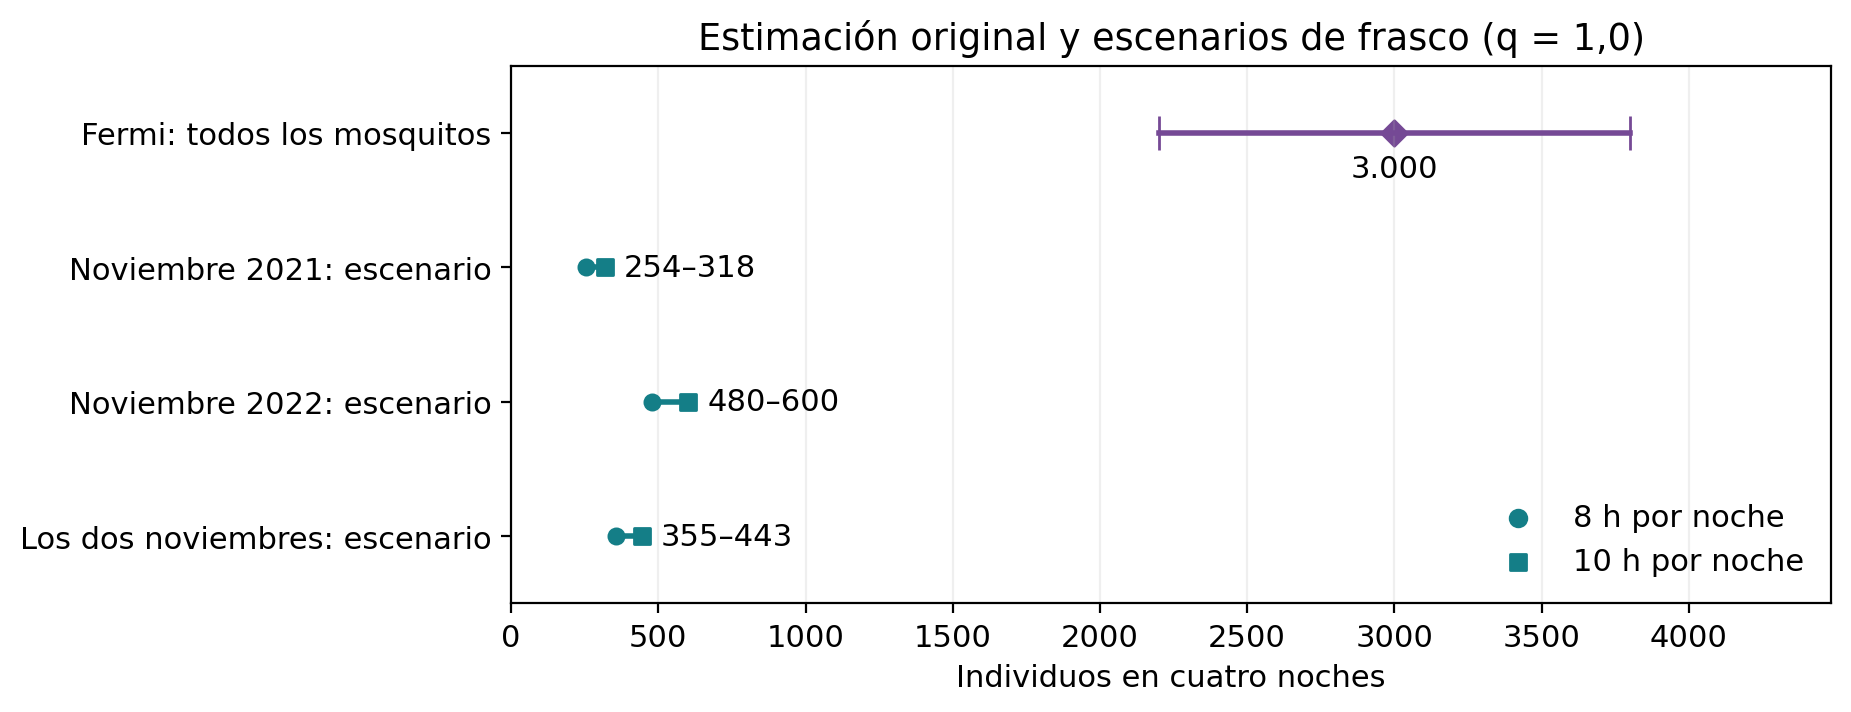

8 h por noche → escenario: 355 Anopheles; Fermi redondeada − escenario = 2.645 individuos.
10 h por noche → escenario: 443 Anopheles; Fermi redondeada − escenario = 2.557 individuos.
Es una distancia entre dos cálculos. Sin conteos de nuestros frascos no hay un error observado.


In [6]:
def tasaConjunta(tabla):
    """Divide el total de individuos por el total de horas de colector; cada hora pesa igual."""
    return tabla.conteo.sum() / tabla.esfuerzo.sum()

puntosNoviembre = puntos.loc[puntos.fecha.dt.month == mesPropuesto]
visitasNoviembre = visitas.loc[visitas.fecha.dt.month == mesPropuesto]
tasaNoviembre = tasaConjunta(puntosNoviembre)
esfuerzoPropio = recipientes * nochesFermi * horasSueno
qEscenario = 1.0  # Es un supuesto sobre el frasco, no un parámetro medido por el INS.
assert qEscenario >= 0, "El rendimiento relativo no puede ser negativo."
escenarioNoviembre = qEscenario * tasaNoviembre * esfuerzoPropio

fig, ax = plt.subplots(figsize=(9.4, 3.7))
colorFermi, colorEscenario = "#754995", "#147e87"
rangoFermi = [fermiOriginal - margenOriginal, fermiOriginal + margenOriginal]
ax.plot(rangoFermi, [0, 0], "|-", lw=2, ms=12, color=colorFermi)
ax.scatter(fermiOriginal, 0, marker="D", s=42, color=colorFermi)
ax.annotate(numero(fermiOriginal, 0), (fermiOriginal, 0), xytext=(0, -16),
            textcoords="offset points", ha="center")
etiquetas = ["Fermi: todos los mosquitos"]
escenarios = [(f"Noviembre {v.fecha.year}", v.tasa) for v in visitasNoviembre.itertuples()]
for i, (nombre, tasa) in enumerate(escenarios + [("Los dos noviembres", tasaNoviembre)], 1):
    # Proyectar la tasa a las horas de frasco de ambos diseños; no es un intervalo estadístico.
    bajo, alto = qEscenario * tasa * esfuerzoPropio
    color = colorEscenario
    ax.hlines(i, bajo, alto, color=color, lw=2)
    ax.scatter(bajo, i, marker="o", color=color, s=30, zorder=3)
    ax.scatter(alto, i, marker="s", color=color, s=30, zorder=3)
    ax.annotate(f"{numero(bajo, 0)}–{numero(alto, 0)}", (alto, i), xytext=(7, 0),
                textcoords="offset points", va="center")
    etiquetas.append(nombre + ": escenario")
ax.set_yticks(range(len(etiquetas)), etiquetas)
ax.set_ylim(len(etiquetas)-.5, -.5)
xmax = max(rangoFermi[-1], *(qEscenario*t*esfuerzoPropio[-1] for _, t in escenarios))
ax.set(xlim=(0, 1.18*xmax), xlabel="Individuos en cuatro noches",
       title=f"Estimación original y escenarios de frasco (q = {numero(qEscenario)})")
ax.scatter([], [], marker="o", color=colorEscenario, label="8 h por noche")
ax.scatter([], [], marker="s", color=colorEscenario, label="10 h por noche")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
plt.show()

for h, estimado in zip(horasSueno, escenarioNoviembre):
    # Restar dos escenarios no estima el sesgo frente a una observación real.
    brecha = fermiOriginal - estimado
    print(f"{h} h por noche → escenario: {numero(estimado, 0)} Anopheles; "
          f"Fermi redondeada − escenario = {numero(brecha, 0)} individuos.")
print("Es una distancia entre dos cálculos. Sin conteos de nuestros frascos no hay un error observado.")

## 3. Comparar los dos puntos de Cheté

En la [imagen del equipo](Datos/cete.png), la estrella roja es Chete1 y la amarilla es Chete2. El sector morado es el que el equipo asocia con la minería. Los códigos del INS no identifican exposición minera ni separan interior y exterior. En nuestro diseño original, cambiar de sector después de dos noches también cambiaba la fecha.

<img src="Datos/cete.png" width="355" alt="Imagen del equipo: Chete1 en rojo, Chete2 en amarillo y el sector señalado en morado.">

Para cada visita restamos la tasa de Chete2 a la de Chete1. Por ejemplo, en noviembre de 2022 la diferencia fue $626/96 - 94/96 = 5{,}54$ individuos por hora de colector. En 18 de 19 visitas la diferencia quedó por encima de cero. La figura de la derecha resume la diferencia media y su incertidumbre; no atribuye la diferencia a la mina.

In [7]:
with (datos / "cauces_pacifico.geojson").open(encoding="utf-8") as fuente:
    cauces = json.load(fuente)["features"]


def dibujarCauces(eje):
    """Añade al eje los cauces en grados de longitud y latitud; no devuelve nada."""
    for tramo in cauces:
        lon, lat = np.asarray(tramo["geometry"]["coordinates"]).T
        eje.plot(lon, lat, color="#9fbfce", lw=1.25, zorder=1)


# Comparar los dos puntos dentro de cada visita evita mezclar fechas.
parejas = puntos.pivot(index="visita", columns="parentEventID", values="cuatroNoches")
assert parejas.notna().all().all()
diferencias = (parejas.Chete1 - parejas.Chete2).to_numpy(dtype=float)


def indicesBloques(cantidad, largo, repeticiones=5000):
    """Devuelve índices de visitas ordenadas: cantidad por réplica, en bloques de largo visitas."""
    azar = np.random.default_rng(semilla)
    # Cada inicio se sortea con reposición. Los bloques abarcan visitas consecutivas
    # observadas, aunque entre ellas falte un mes; se recorta solo el último bloque.
    inicios = azar.integers(0, cantidad - largo + 1, size=(repeticiones, math.ceil(cantidad / largo)))
    bloques = inicios[:, :, None] + np.arange(largo)
    return bloques.reshape(repeticiones, -1)[:, :cantidad]


def intervaloDiferencia(valores, largo):
    """Estima un IC del 95 % para la media de diferencias por 96 h, con bloques de largo visitas."""
    muestras = valores[indicesBloques(len(valores), largo)].mean(axis=1)
    return np.quantile(muestras, [.025, .975])


icBajo, icAlto = intervaloDiferencia(diferencias, 2)
visitas12 = puntos.loc[puntos.horas == 12, "visita"].unique()
sinBase = diferencias[parejas.index.isin(visitas12)]
sinUna = [(diferencias.sum() - valor) / (len(diferencias) - 1) for valor in diferencias]

# Solo la presentación se divide por 96 h; diferencias e intervalos internos conservan su escala.
omisionBaja, omisionAlta = min(sinUna) / esfuerzoObjetivo, max(sinUna) / esfuerzoObjetivo
print(f"Al omitir una visita: de {numero(omisionBaja, 2)} a {numero(omisionAlta, 2)} "
      "individuos de diferencia media por hora de colector (no es un intervalo de confianza).")
# Los bloques de 2 y 3 son dos tamaños de remuestreo, no números de visita.
for largo in (2, 3):
    bajoHora, altoHora = intervaloDiferencia(sinBase, largo) / esfuerzoObjetivo
    print(f"Solo jornadas de 12 h, IC del 95 % con bloques de {largo} visitas: "
          f"de {numero(bajoHora, 2)} a {numero(altoHora, 2)} individuos por hora de colector.")

Al omitir una visita: de 2,36 a 2,79 individuos de diferencia media por hora de colector (no es un intervalo de confianza).
Solo jornadas de 12 h, IC del 95 % con bloques de 2 visitas: de 2,16 a 3,87 individuos por hora de colector.
Solo jornadas de 12 h, IC del 95 % con bloques de 3 visitas: de 2,13 a 3,80 individuos por hora de colector.


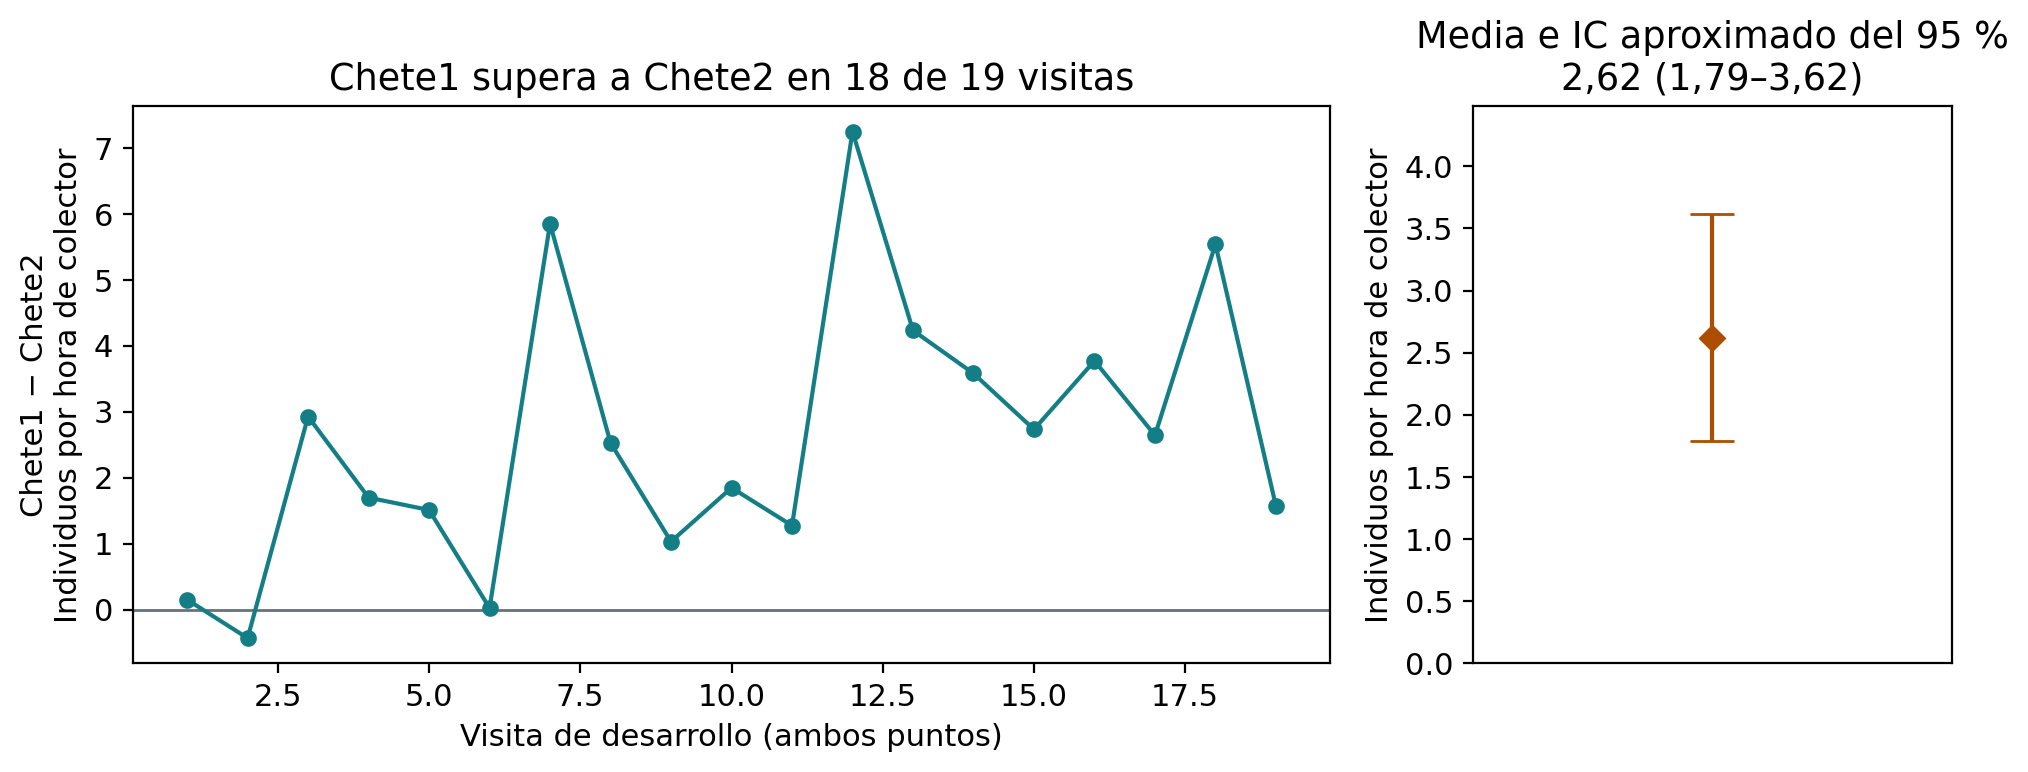

In [8]:
# Las diferencias e IC internos ya están a 96 h; dividir solo para mostrarlos.
mediaDif = diferencias.mean()
diferenciaHora = diferencias / esfuerzoObjetivo
mediaHora, bajoHora, altoHora = np.array([mediaDif, icBajo, icAlto]) / esfuerzoObjetivo
fig, (ax, resumen) = plt.subplots(
    1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [2.5, 1]}
)
ax.axhline(0, color="#68727b", lw=1)
ax.plot(parejas.index, diferenciaHora, "o-", color="#147e87", ms=5)
ax.set(xlabel="Visita de desarrollo (ambos puntos)",
       ylabel=f"Chete1 − Chete2\n{unidadTasa}",
       title=f"Chete1 supera a Chete2 en {(diferencias > 0).sum()} de {len(diferencias)} visitas")
resumen.errorbar([0], [mediaHora], yerr=[[mediaHora - bajoHora], [altoHora - mediaHora]],
                 fmt="D", capsize=8, color=coloresFigura["focal"])
resumen.axhline(0, color="#68727b", lw=1)
resumen.set(xticks=[], ylim=(min(0, bajoHora * 1.15), altoHora * 1.24),
            ylabel=unidadTasa,
            title=f"Media e IC aproximado del 95 %\n"
                  f"{numero(mediaHora, 2)} ({numero(bajoHora, 2)}–{numero(altoHora, 2)})")
fig.tight_layout()
plt.show()

## 4. Noviembre, diciembre y las especies registradas

En la [Fermi](../EstimacionFermi_00/estimacion_inicial.md) propusimos esos dos meses y la noche. Para comparar meses sumamos sus individuos y sus horas antes de dividir. Un mes sin visita no cuenta como cero. Sin un grupo diurno ni datos de cada hora del reloj no podemos comprobar una ventaja de la noche, aunque el [ciclo descrito por los CDC](https://www.cdc.gov/mosquitoes/about/life-cycle-of-anopheles-mosquitoes.html) haya motivado la idea.

El [mapa inicial de distribución](https://es.wikipedia.org/wiki/Anopheles) nos hizo esperar *An. darlingi* y *An. albimanus*. De esas dos, solo aparece *albimanus*; también se registraron *neivai* y *apicimacula*. *An. nuneztovari* C figura en el contexto colombiano, no en las capturas del archivo. Los palpos largos son un rasgo [bibliográfico](https://www.cdc.gov/dpdx/malaria/index.html), no una medición de estas hembras adultas. Una base dedicada a *Anopheles* no permite concluir que no haya *Aedes* o *Culex*.

In [9]:
aniosContraste = [2021, 2022]
mesesBimestre = [11, 12]
sitioChete = ("Timbiquí", "Cheté")
fechasContraste = eventosDesarrollo.fecha.dropna()
if not (fechasContraste.dt.year.lt(2023) & fechasContraste.dt.day.eq(1)).all():
    raise ValueError("Los contrastes requieren meses de desarrollo anteriores a 2023.")

# Solo entran eventos con un mes asignable en los dos años de desarrollo.
eventosContraste = eventosDesarrollo.loc[eventosDesarrollo.fecha.dt.year.isin(aniosContraste)].copy()
eventosContraste["anio"] = eventosContraste.fecha.dt.year
eventosContraste["mes"] = eventosContraste.fecha.dt.month
enChete = pd.MultiIndex.from_frame(eventosContraste[camposSitio]).isin([sitioChete])
cheteCalendario = eventosContraste.loc[enChete]
mesChete = cheteCalendario.mes
enBimestre = mesChete.isin(mesesBimestre)
gruposCalendario = {
    "Noviembre": mesChete.eq(11), "Diciembre": mesChete.eq(12),
    "Resto": ~enBimestre, "Bimestre": enBimestre,
}
tasasCalendario = pd.DataFrame(index=aniosContraste)
for nombre, filtro in gruposCalendario.items():
    # La tasa se pondera por horas de colector: cada evento aporta su esfuerzo real.
    totales = cheteCalendario.loc[filtro].groupby("anio")[["conteo", "esfuerzo"]].sum()
    tasasCalendario[nombre] = esfuerzoObjetivo * totales.conteo / totales.esfuerzo
# Un grupo sin observaciones no se debe tratar como cero individuos.
assert tasasCalendario.notna().all().all()

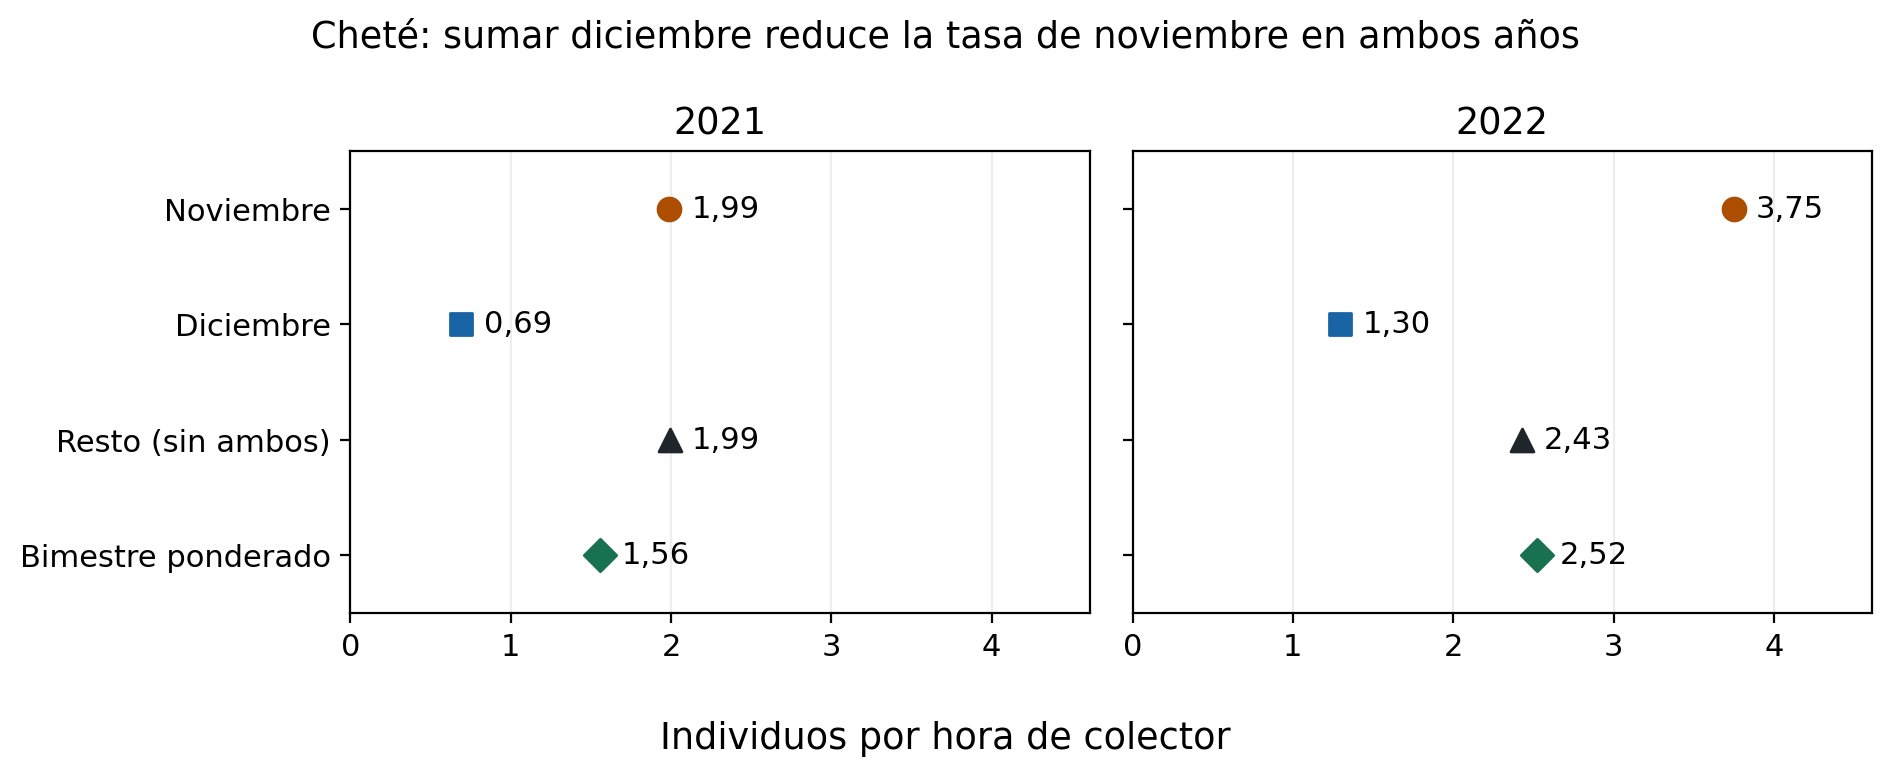

In [10]:
# Reexpresar las tasas ya ponderadas por el esfuerzo; no promediar los meses.
calendarioHora = tasasCalendario / esfuerzoObjetivo
figBimestre, ejes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(9.6, 3.8))
categorias = ["Noviembre", "Diciembre", "Resto (sin ambos)", "Bimestre ponderado"]
marcasCalendario = ["o", "s", "^", "D"]
tonosCalendario = [coloresFigura[k] for k in ("focal", "regional", "observado", "historica")]
for eje, (anio, tasas) in zip(ejes, calendarioHora.iterrows()):
    # Cada fila mantiene su símbolo y posición para comparar ambos años.
    for i, (tasa, marca, color) in enumerate(zip(tasas, marcasCalendario, tonosCalendario)):
        eje.scatter(tasa, i, marker=marca, color=color, s=68, zorder=3)
        eje.annotate(numero(tasa, 2), (tasa, i), xytext=(8, 0),
                     textcoords="offset points", va="center")
    eje.set_yticks(range(len(categorias)), categorias)
    eje.set(title=str(anio), ylim=(3.5, -.5),
            xlim=(0, 1.23 * calendarioHora.max().max()))
    eje.grid(axis="x", alpha=.22)
figBimestre.supxlabel(unidadTasa)
figBimestre.suptitle("Cheté: sumar diciembre reduce la tasa de noviembre en ambos años")
figBimestre.tight_layout()
plt.show()

Noviembre superó a diciembre en 2021 y en 2022. La respuesta cambia si juntamos los dos meses y los comparamos con los demás: el bimestre quedó por debajo del resto en 2021 y apenas por encima en 2022. Los datos no muestran una ventaja consistente del bimestre.

Para comparar especies usamos localidades con registros en noviembre y diciembre de ambos años. Los porcentajes siguientes se refieren a las capturas de esos cuatro meses, no a todas las especies que viven allí.

In [11]:
# Unir por evento conserva las filas de especie que no tienen una fecha propia.
eventosBimestre = eventosContraste.loc[eventosContraste.mes.isin(mesesBimestre)]
ocurrenciasBimestre = filasRegionalesDesarrollo.merge(
    eventosBimestre[claveEvento + ["fecha"]], on=claveEvento, validate="many_to_one"
)
# Solo se comparan localidades presentes en noviembre y diciembre de ambos años.
cobertura = ocurrenciasBimestre.groupby(camposSitio).fecha.nunique()
panel = cobertura[cobertura.eq(len(aniosContraste) * len(mesesBimestre))].index
nExternas = len(panel.drop(sitioChete))
sitios = pd.MultiIndex.from_frame(ocurrenciasBimestre[camposSitio])
enPanel = sitios.isin(panel)
panelEspecies = ocurrenciasBimestre.loc[enPanel].copy()
panelEspecies["grupo"] = np.where(sitios[enPanel].isin([sitioChete]), "Cheté", "Externas")
panelEspecies["individuos"] = panelEspecies.individualCount.astype(int)
conteosEspecies = panelEspecies.pivot_table(
    index="grupo", columns="scientificName", values="individuos", aggfunc="sum", fill_value=0
)
# Los porcentajes son del total de individuos de cada grupo, no promedios por localidad.
totalesEspecies = conteosEspecies.sum(axis=1)
porcentajesEspecies = 100 * conteosEspecies.div(totalesEspecies, axis=0)

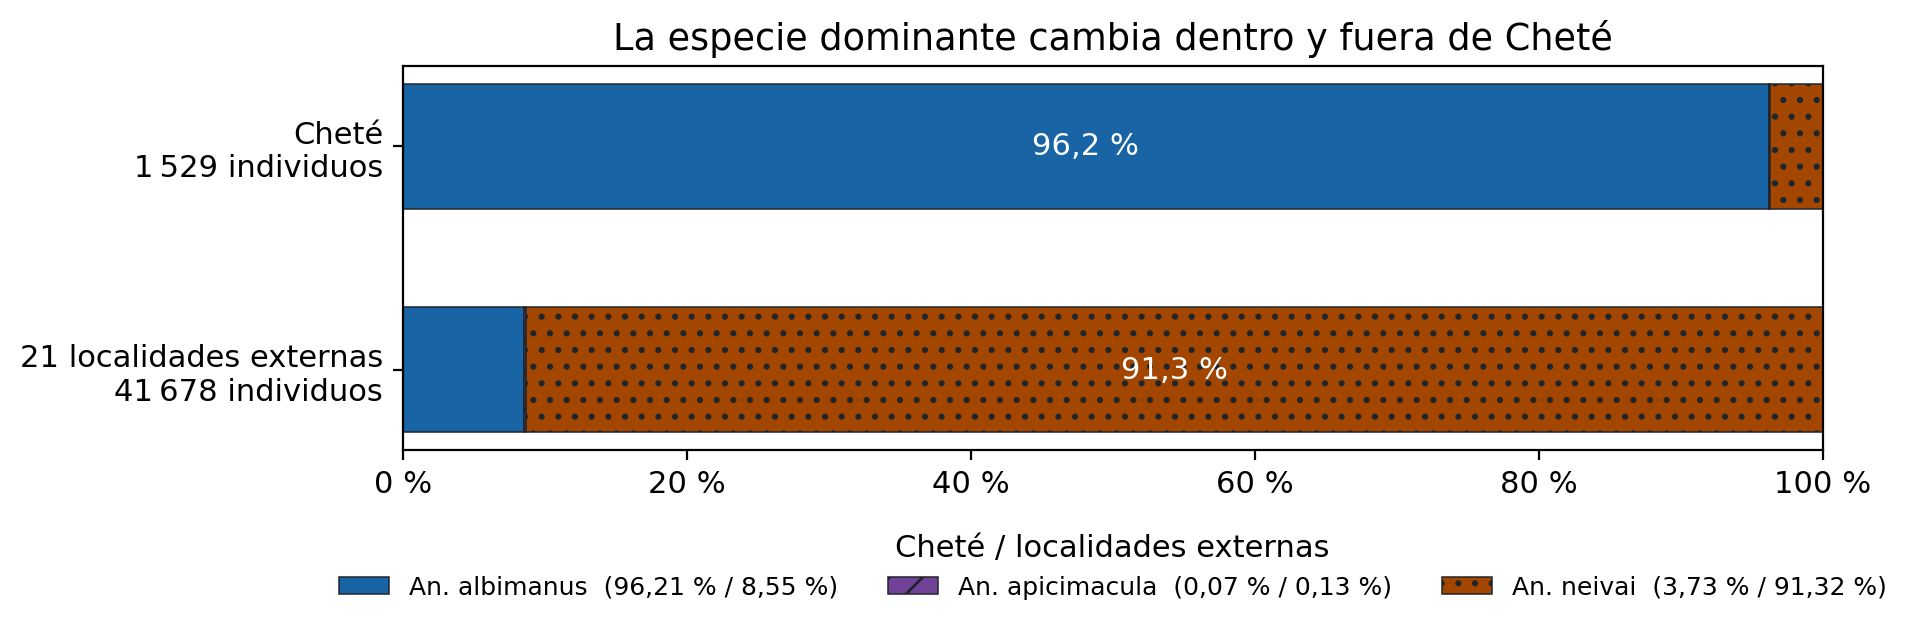

In [12]:
figEspecies, eje = plt.subplots(figsize=(9.6, 3.4))
grupos = ["Cheté", "Externas"]
nombres = ["Cheté", f"{nExternas} localidades externas"]
izquierda = np.zeros(len(grupos))
estilosEspecie = [("#1864a5", ""), ("#704398", "//"), ("#a34600", "..")]
for especie, (color, trama) in zip(porcentajesEspecies.columns, estilosEspecie):
    # Apilar proporciones dentro de cada grupo, sin cambiar el denominador.
    anchos = porcentajesEspecies.loc[grupos, especie].to_numpy()
    porcentajes = " / ".join(f"{p:.2f} %".replace(".", ",") for p in anchos)
    nombre = especie.replace("Anopheles ", "An. ")
    eje.barh(grupos, anchos, left=izquierda, height=.56, color=color, edgecolor="#20252b", lw=.55, hatch=trama,
             label=f"{nombre}  ({porcentajes})")
    # La leyenda detalla los segmentos pequeños que no admiten texto dentro de la barra.
    for y, ancho in enumerate(anchos):
        if ancho > 50:
            eje.text(izquierda[y] + ancho/2, y, f"{ancho:.1f} %".replace(".", ","),
                     ha="center", va="center", color="white")
    izquierda += anchos
eje.set_yticks(range(len(grupos)), [
    f"{nombre}\n{totalesEspecies[g]:,} individuos".replace(",", "\u202f")
    for nombre, g in zip(nombres, grupos)
])
eje.invert_yaxis()
eje.set(xlim=(0, 100), title="La especie dominante cambia dentro y fuera de Cheté")
eje.set_xticks(range(0, 101, 20), [f"{p} %" for p in range(0, 101, 20)])
eje.legend(title="Cheté / localidades externas", loc="upper center",
           bbox_to_anchor=(.5, -.16), ncol=3, frameon=False, fontsize=9)
figEspecies.tight_layout()
plt.show()

En Cheté predominó *albimanus* (1.471 de 1.529 individuos); fuera de Cheté, *neivai* (38.059 de 41.678 en las localidades comparables).

## 5. Fuera de Cheté, ¿se repite la ventaja de un sitio sobre otro?

En Cheté, Chete1 superó a Chete2 en 18 de 19 visitas. Quisimos saber si en otras localidades el sitio con más capturas por hora en 2021 también llevaba ventaja en 2022. Dentro de cada localidad escogimos dos puntos, A y B. Para un mes con datos en ambos puntos y ambos años, restamos la tasa de B a la de A. Repetimos la cuenta con los demás meses comparables y tomamos la mediana de las diferencias de cada año.

En Joanico, por ejemplo, la diferencia fue −0,13 individuos por hora de colector en 2021 y +0,77 en 2022. B llevaba una pequeña ventaja el primer año y A lo superó el segundo. Por eso Joanico aparece como una cruz naranja en la gráfica de la derecha. Cada símbolo representa un par de sitios. Su posición horizontal muestra la diferencia de 2021 y la vertical muestra la de 2022. Los círculos azules señalan los pares donde el mismo sitio quedó por encima ambos años. En el mapa de la izquierda, los cuadrados ubican puntos de localidades que aportaron al menos un par comparable.

Con al menos tres meses comunes encontramos 17 pares en 11 localidades. En 14 pares se mantuvo la ventaja del mismo sitio. Al exigir al menos cinco meses comunes y coordenadas inequívocas y distintas para los dos sitios, se mantuvo en 12 de 15 pares. Algunos pares comparten sitio, así que un mismo punto puede influir en varias comparaciones.

In [13]:
externos = eventosContraste.loc[~enChete]
clavePunto = [*camposSitio, "punto"]
# Si hubo varios eventos en el mismo punto y mes, se suman individuos y horas antes de dividir.
mensual = externos.groupby(clavePunto + ["anio", "mes"], as_index=False)[["conteo", "esfuerzo"]].sum()
mensual["tasa"] = esfuerzoObjetivo * mensual.conteo / mensual.esfuerzo
lon, lat = "decimalLongitude", "decimalLatitude"
coordenadasDesarrollo = filasRegionalesDesarrollo.loc[
    filasRegionalesDesarrollo.geodeticDatum.eq("WGS84"), [*camposSitio, "parentEventID", lon, lat]
].rename(columns={"parentEventID": "punto"})
coordenadasDesarrollo[[lon, lat]] = coordenadasDesarrollo[[lon, lat]].apply(pd.to_numeric, errors="coerce")
validas = coordenadasDesarrollo[lon].between(-180, 180) & coordenadasDesarrollo[lat].between(-90, 90)
# Repetir una coordenada no crea otra posición; discrepar sí impide asignar una sola al punto.
posicionesPares = (coordenadasDesarrollo.loc[validas].drop_duplicates()
                   .drop_duplicates(clavePunto, keep=False).set_index(clavePunto))

filasPares = []
for sitio, tabla in mensual.groupby(camposSitio):
    tasas = tabla.pivot(index="mes", columns=["punto", "anio"], values="tasa")
    # El orden alfabético fija la dirección de A menos B en ambos años.
    for a, b in combinations(sorted(tabla.punto.unique()), 2):
        columnas = [(punto, anio) for punto in (a, b) for anio in aniosContraste]
        # Solo cuentan meses del calendario con datos en los dos puntos y en ambos años.
        comunes = tasas.reindex(columns=columnas).dropna()
        if len(comunes) < 3:
            continue
        medianas = (comunes[a] - comunes[b]).median()
        ubicaciones = posicionesPares.reindex([(*sitio, a), (*sitio, b)]).dropna()
        estricto = len(comunes) >= 5 and len(ubicaciones.drop_duplicates()) == 2
        filasPares.append((*sitio, *medianas, len(comunes), estricto))
primero, segundo = aniosContraste
pares = pd.DataFrame(filasPares, columns=[*camposSitio, primero, segundo, "n_meses", "estricto"])
# Un producto positivo indica el mismo orden en los dos años; un cero queda aparte.
producto = pares[primero] * pares[segundo]
pares["signo"] = np.select([producto.gt(0), producto.lt(0)], ["Conserva", "Cambia"], "Mediana cero")
resumenPares = {
    nombre: {
        "conservan": int(tabla.signo.eq("Conserva").sum()),
        "n_pares": len(tabla),
        "n_localidades": len(tabla[camposSitio].drop_duplicates()),
    }
    for nombre, tabla in [("base", pares), ("cinco_meses", pares.loc[pares.n_meses >= 5]),
                          ("sensibilidad", pares.loc[pares.estricto])]
}

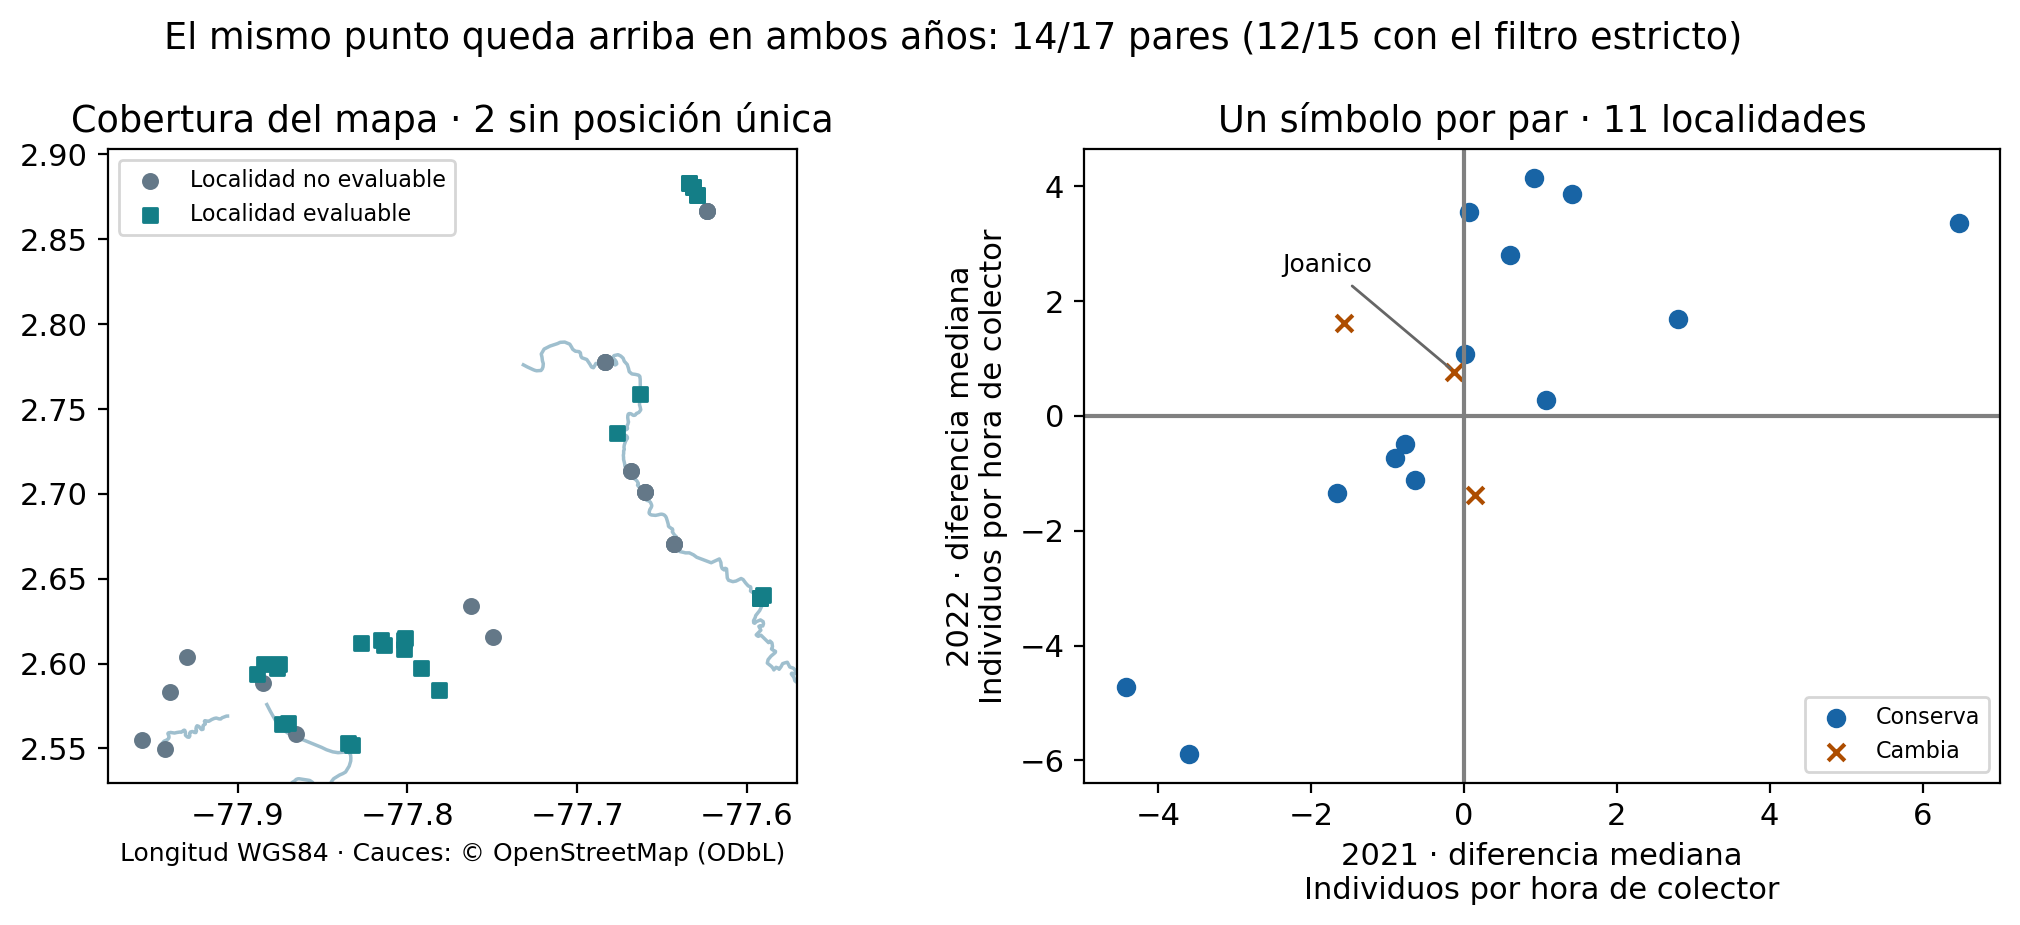

In [14]:
figPares, (mapa, nube) = plt.subplots(1, 2, figsize=(10.8, 4.7))
dibujarCauces(mapa)
localidades = pd.MultiIndex.from_frame(externos[camposSitio].drop_duplicates())
evaluables = pd.MultiIndex.from_frame(pares[camposSitio].drop_duplicates())
puntosMapa = posicionesPares.loc[posicionesPares.index.droplevel("punto").isin(localidades)].reset_index()
sitiosMapa = pd.MultiIndex.from_frame(puntosMapa[camposSitio])
hayPar = sitiosMapa.isin(evaluables)
for mascara, etiqueta, marcador, color in [
    (~hayPar, "Localidad no evaluable", "o", "#647888"),
    (hayPar, "Localidad evaluable", "s", "#147e87"),
]:
    # El mapa ubica puntos; la nube compara pares completos, no posiciones individuales.
    ubicaciones = puntosMapa.loc[mascara]
    mapa.scatter(ubicaciones[lon], ubicaciones[lat], marker=marcador,
                 color=color, s=26, label=etiqueta, zorder=3)
margenMapa = .02  # Grados de margen alrededor de las posiciones observadas.
if len(puntosMapa):
    mapa.set(xlim=(puntosMapa[lon].min() - margenMapa, puntosMapa[lon].max() + margenMapa),
             ylim=(puntosMapa[lat].min() - margenMapa, puntosMapa[lat].max() + margenMapa))
sinMapa = len(localidades.difference(sitiosMapa))
mapa.set(title=f"Cobertura del mapa · {sinMapa} sin posición única", aspect="equal")
mapa.set_xlabel("Longitud WGS84 · Cauces: © OpenStreetMap (ODbL)", fontsize=9)
mapa.legend(loc="upper left", fontsize=8)
coloresSigno = {"Conserva": "#1864a5", "Cambia": "#ad4d00", "Mediana cero": "#20252b"}
# Las medianas son diferencias A − B a 96 h; el signo no cambia al pasarlas a una hora.
for signo, grupo in pares.groupby("signo", sort=False):
    nube.scatter(grupo[primero] / esfuerzoObjetivo, grupo[segundo] / esfuerzoObjetivo,
                 color=coloresSigno[signo],
                 marker={"Conserva": "o", "Cambia": "x", "Mediana cero": "+"}[signo], label=signo)
nube.axhline(0, color=".5")
nube.axvline(0, color=".5")
basePares, filtroPares = (resumenPares[k] for k in ["base", "sensibilidad"])
nube.set(title=f"Un símbolo por par · {basePares['n_localidades']} localidades",
         xlabel=f"{primero} · diferencia mediana\n{unidadTasa}",
         ylabel=f"{segundo} · diferencia mediana\n{unidadTasa}")
ejemploPar = pares.loc[pares.locality.eq("Joanico")].iloc[0]
nube.annotate("Joanico", (ejemploPar[primero] / esfuerzoObjetivo, ejemploPar[segundo] / esfuerzoObjetivo),
              xytext=(-62, 36),
              textcoords="offset points", fontsize=9, arrowprops={"arrowstyle": "-", "color": ".4"})
nube.legend(fontsize=8, loc="lower right")
figPares.suptitle(f"El mismo punto queda arriba en ambos años: {basePares['conservan']}/{basePares['n_pares']} pares "
                 f"({filtroPares['conservan']}/{filtroPares['n_pares']} con el filtro estricto)")
figPares.tight_layout()
plt.show()

## 6. ¿Qué datos se parecen más entre sí?

En la opción A dejamos fijo el lugar, Cheté, y comparamos sus meses. En B dejamos fijo noviembre y comparamos localidades de Timbiquí. Medimos cuánto se dispersan las tasas respecto de su media: el coeficiente de variación es la desviación estándar dividida por la media. Una barra baja significa menos dispersión, no más predicciones acertadas.

B fue menos dispersa en 2021 y A en 2022. Dando igual peso a los dos años, A tuvo 47,8 % frente a 63,5 % de B. Por eso el bosque local usa todos los meses de Cheté. Esta elección se hizo con el desarrollo completo de 2021–2022, no con la reserva de 2023.

In [15]:
opciones = {"A": "Cheté, todos los meses", "B": "Timbiquí, noviembre"}


def dispersionPorAnio(eventos):
    """Compara tasas por hora de eventos fechados; devuelve CV y RIC/mediana por opción y año."""
    x = eventos.dropna(subset=["fecha"]).assign(anio=lambda tabla: tabla.fecha.dt.year)
    timbiqui = x.loc[x.county.eq("Timbiquí")]
    # A compara meses dentro de Cheté; B compara localidades durante noviembre.
    muestras = {
        "A": (timbiqui.loc[timbiqui.locality.eq("Cheté")], "fecha"),
        "B": (timbiqui.loc[timbiqui.fecha.dt.month.eq(mesPropuesto)], "locality"),
    }
    filas = []
    for opcion, (muestra, unidad) in muestras.items():
        grupos = muestra.groupby(["anio", unidad])[["conteo", "esfuerzo"]].sum()
        tasas = grupos.conteo / grupos.esfuerzo
        for anio, serie in tasas.groupby(level="anio"):
            cv = serie.std() / serie.mean()
            robusta = (serie.quantile(.75) - serie.quantile(.25)) / serie.median()
            filas.append((opcion, anio, cv, robusta))
    return pd.DataFrame(filas, columns=["opcion", "anio", "CV", "RIC/mediana"])


dispersion = dispersionPorAnio(eventosDesarrollo)
# Cada año pesa igual, aunque tenga un número distinto de meses o localidades.
promedio = dispersion.groupby("opcion").CV.mean()
opcionElegida = promedio.idxmin()
print(f"A: {promedio['A']:.1%} · B: {promedio['B']:.1%}. Menor promedio: {opciones[opcionElegida]}.")

# Dos comprobaciones de sensibilidad: acotar a jornadas de 12 h o
# medir la dispersión con el rango intercuartílico dividido por la mediana.
jornadas12 = dispersionPorAnio(eventosDesarrollo.loc[eventosDesarrollo.horas.eq(12)])
print("Opción con menor dispersión: solo jornadas de 12 h (CV):",
      jornadas12.groupby("opcion").CV.mean().idxmin(),
      "· todas las jornadas (rango intercuartílico / mediana):",
      dispersion.groupby("opcion")["RIC/mediana"].mean().idxmin())

A: 47.8% · B: 63.5%. Menor promedio: Cheté, todos los meses.
Opción con menor dispersión: solo jornadas de 12 h (CV): A · todas las jornadas (rango intercuartílico / mediana): A


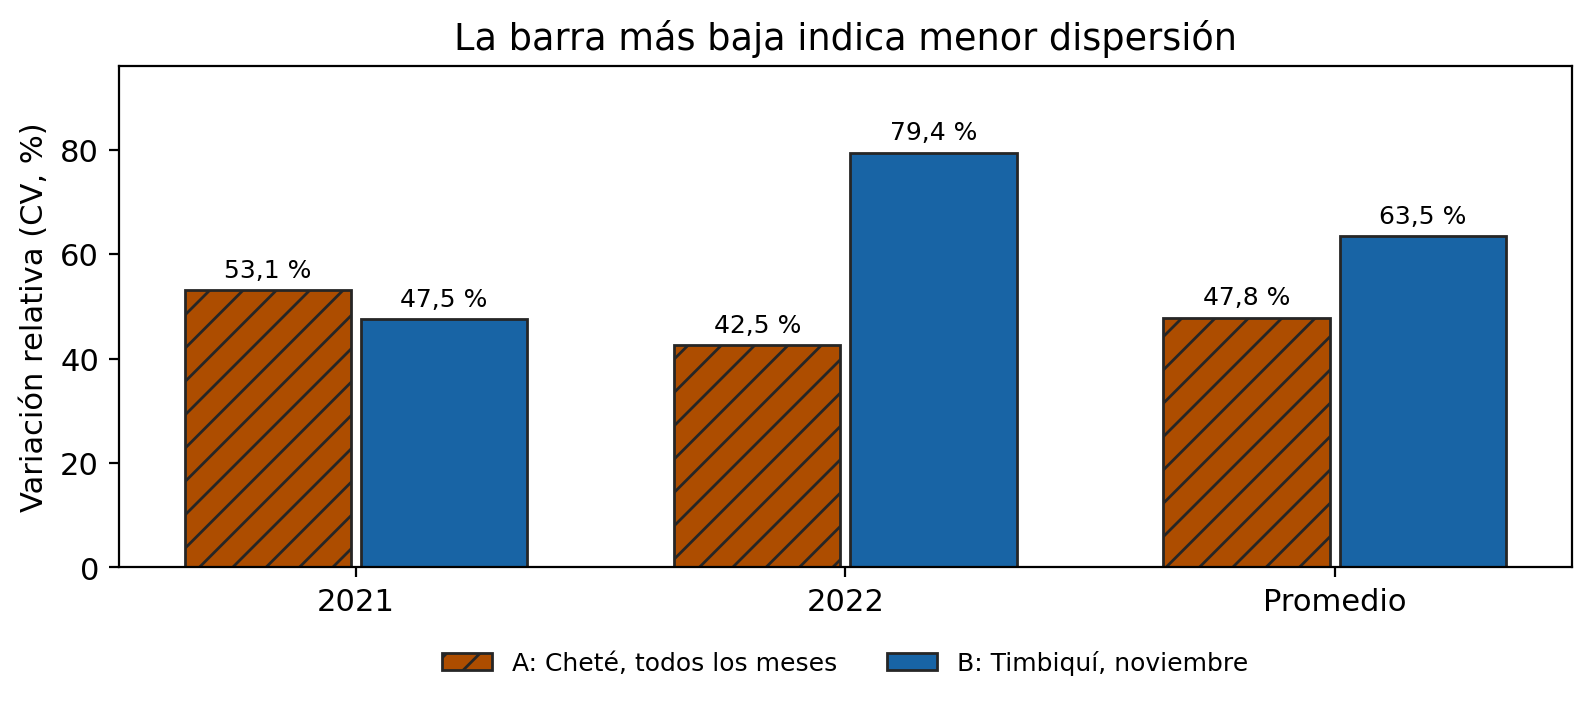

In [16]:
cvAnual = 100 * dispersion.pivot(index="anio", columns="opcion", values="CV")
cvAnual.loc["Promedio"] = 100 * promedio
fig, ax = plt.subplots(figsize=(8.1, 3.7))
x = np.arange(len(cvAnual))
# El CV no tiene unidad; comparar porcentajes dentro de cada año y en el promedio.
for opcion, dx, relleno, trama in [
    ("A", -.18, coloresFigura["focal"], "//"),
    ("B", .18, coloresFigura["regional"], ""),
]:
    barras = ax.bar(x + dx, cvAnual[opcion], .34, color=relleno, edgecolor=".15", hatch=trama,
                    label=f"{opcion}: {opciones[opcion]}")
    ax.bar_label(barras, labels=[numero(v) + " %" for v in cvAnual[opcion]], padding=3, fontsize=9)
ax.set(xticks=x, xticklabels=cvAnual.index.astype(str), ylabel="Variación relativa (CV, %)",
       ylim=(0, 1.21*cvAnual.max().max()), title="La barra más baja indica menor dispersión")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2, frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Cuánto puede variar el promedio histórico

Un bloque de dos son dos visitas vecinas en la lista; por ejemplo, febrero y marzo de 2022. Un bloque de tres puede ser febrero, marzo y mayo: en abril no hubo visita. Los dos puntos de cada visita siempre van juntos.

Sorteamos bloques con reposición hasta reunir 19 visitas; un bloque puede repetirse y se recorta el sobrante. Dividimos sus individuos totales por sus horas totales. Repetimos 5.000 veces para ver cuánto varía el promedio sin separar todas las visitas vecinas.

El punto indica el promedio observado, 2,19 por hora. Las rayas contienen el 95 % central de los promedios remuestreados: aproximadamente 1,84–2,57 con bloques de dos y 1,80–2,56 con bloques de tres. No son límites para una visita nueva ni para los frascos.

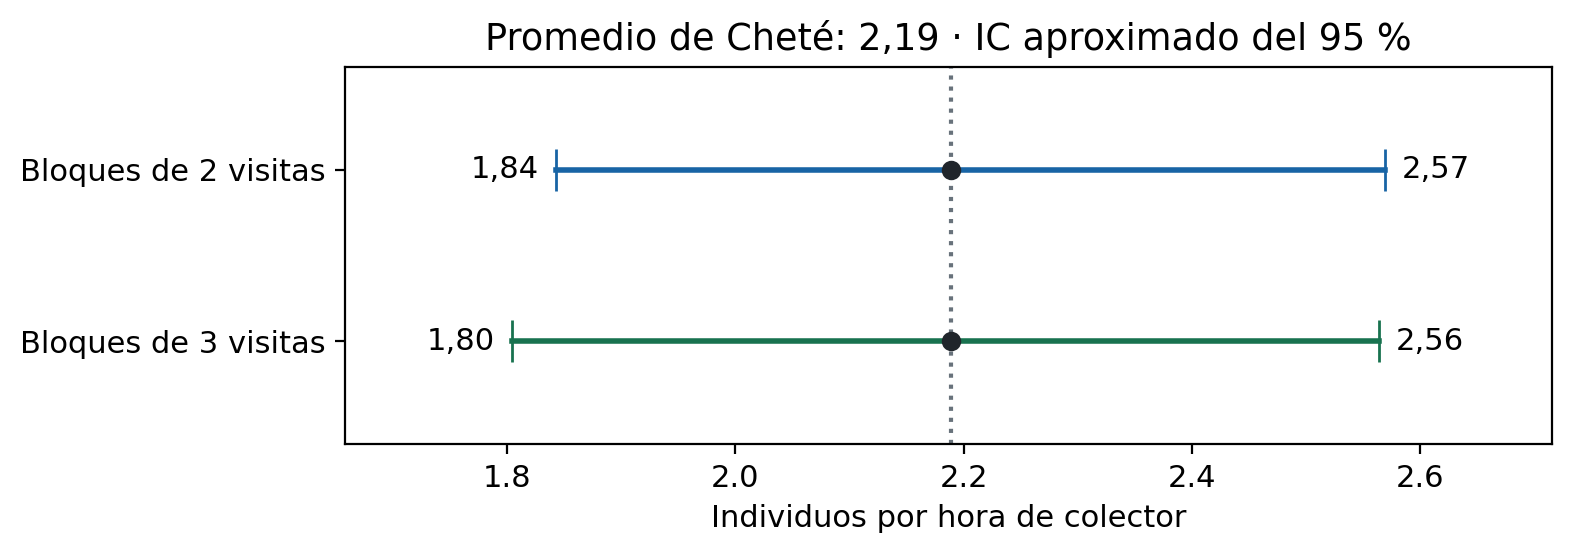

In [17]:
conteos = visitas.conteo.to_numpy(dtype=float)
horas = visitas.esfuerzo.to_numpy(dtype=float)
promedioOriginal = esfuerzoObjetivo * tasaConjunta(visitas)
mediaHora = promedioOriginal / esfuerzoObjetivo
fig, ax = plt.subplots(figsize=(8, 2.9))
limitesMedia = []
for y, largo in enumerate((2, 3)):
    # Cada réplica agrupa visitas consecutivas; la razón pondera las horas de cada visita.
    indices = indicesBloques(len(visitas), largo)
    promedio96 = esfuerzoObjetivo * conteos[indices].sum(axis=1) / horas[indices].sum(axis=1)
    bajo, alto = np.quantile(promedio96, [.025, .975])
    limitesMedia.extend([bajo, alto])
    bajoHora, altoHora = np.array([bajo, alto]) / esfuerzoObjetivo
    color = coloresFigura["regional" if largo == 2 else "historica"]
    ax.plot([bajoHora, altoHora], [y, y], "|-", ms=15, lw=2, color=color)
    ax.scatter(mediaHora, y, color=coloresFigura["observado"], zorder=3)
    # Etiquetar los dos extremos del 95 % central, no el rango de visitas individuales.
    for v, dx, alineacion in [(bajoHora, -6, "right"), (altoHora, 6, "left")]:
        ax.annotate(numero(v, 2), (v, y), xytext=(dx, 0), textcoords="offset points",
                    ha=alineacion, va="center")
ax.axvline(mediaHora, ls=":", color="#68727b", zorder=0)
ax.set(yticks=[0, 1], yticklabels=["Bloques de 2 visitas", "Bloques de 3 visitas"], ylim=(1.6, -.6),
       xlim=((min(limitesMedia)-14) / esfuerzoObjetivo, (max(limitesMedia)+14) / esfuerzoObjetivo),
       xlabel=unidadTasa,
       title=f"Promedio de Cheté: {numero(mediaHora, 2)} · IC aproximado del 95 %")
fig.tight_layout()
plt.show()

## 7. ¿Cuántos *Anopheles* por hora esperamos en la próxima visita?

Para estimar la captura de nuestros frascos sigue faltando $q$. Con los registros del INS podemos responder otra pregunta. Si solo conocemos las visitas anteriores, ¿qué tan cerca podemos quedar de la tasa que observará el colector en la siguiente? Para cada visita calculamos los individuos por hora y, al ajustar los modelos, dimos más peso a las visitas con más horas de observación.

Probamos primero dos reglas sencillas. Una repite la tasa de la última visita a Cheté. La otra calcula la tasa histórica dividiendo todos los individuos capturados en Cheté hasta esa fecha por todas las horas trabajadas allí. Por ejemplo, si nos situamos el 1 de enero de 2023, ambas reglas solo pueden usar visitas terminadas hasta diciembre de 2022.

Después probamos tres modelos para ver si el calendario, el lugar o la última tasa conocida ayudaban a reducir el error.

| Modelo | Datos anteriores a enero de 2023 | Cómo estima la tasa de una visita |
|---|---|---|
| Regresión de Poisson | 19 visitas de Cheté | Ajusta una curva según el tiempo transcurrido y el mes del año. La tasa toma valores positivos y puede superar el máximo observado. |
| Bosque regional | 483 visitas de 27 combinaciones de municipio y localidad | Sus árboles agrupan visitas según el sitio, la fecha y la última tasa conocida del sitio. El bosque promedia las predicciones de los árboles. |
| Bosque de Cheté | Las mismas 19 visitas locales | Usa el mismo procedimiento con las visitas de Cheté. Como el sitio es siempre el mismo, las diferencias entre visitas vienen del calendario y de la tasa anterior. |

Cada bosque promedia tasas dentro del rango que vio al entrenarse. El regional vio tasas de 0,01 a 20,74 por hora y el local, de 0,10 a 4,67. Esos límites describen los datos con los que aprendió cada uno.

Para evaluar Poisson seguimos el orden de las visitas. Las primeras dos rondas de tres visitas sirvieron para elegir cuánto suavizar la curva. Con los errores de las dos rondas siguientes calculamos un margen orientativo. Por último fijamos los pronósticos de enero, febrero y marzo antes de consultar las capturas reservadas.

In [18]:
def variables(fechas):
    """Convierte cada fecha en tiempo transcurrido (años), seno y coseno del mes."""
    fechas = pd.DatetimeIndex(fechas)
    meses = (fechas.year - 2021) * 12 + fechas.month - 1
    # En un círculo diciembre queda al lado de enero, no a once meses de distancia.
    angulo = 2 * np.pi * (fechas.month - 1) / 12
    return np.column_stack([meses / 12, np.sin(angulo), np.cos(angulo)])

def ajustar(entrenamiento, alpha):
    """Ajusta Poisson a las tasas por hora del pasado; devuelve la escala y el modelo."""
    escala = StandardScaler()
    x = escala.fit_transform(variables(entrenamiento.fecha))
    # Una visita con el doble de horas aporta el doble de peso, no el doble de tasa.
    modelo = PoissonRegressor(alpha=alpha, max_iter=2000, tol=1e-8)
    modelo.fit(x, entrenamiento.tasa.to_numpy(dtype=float),
               sample_weight=entrenamiento.esfuerzo.to_numpy(dtype=float))
    return escala, modelo

def predecir(ajuste, fechas):
    """Aplica la escala ya aprendida y expresa la predicción de Poisson por 96 h."""
    escala, modelo = ajuste
    return esfuerzoObjetivo * modelo.predict(escala.transform(variables(fechas)))

def referencias(entrenamiento, cantidad):
    """Repite la última tasa y la histórica de Cheté para cada mes, en equivalentes por 96 h."""
    # Conservamos el nombre original de la referencia en la firma de Poisson:
    # Fermi revisada aquí es la tasa humana histórica, no el escenario de los frascos.
    return {
        "Última visita": np.repeat(entrenamiento.cuatroNoches.iloc[-1], cantidad),
        "Fermi revisada": np.repeat(esfuerzoObjetivo * tasaConjunta(entrenamiento), cantidad),
    }

In [19]:
# El inicio marca dónde termina el entrenamiento; las tres visitas siguientes comprueban la predicción.
# Aquí no sorteamos bloques: una predicción nunca recibe información de la visita que intenta anticipar.
bloques = [(7, 10), (10, 13), (13, 16), (16, 19)]
for inicio, fin in bloques:
    assert visitas.iloc[:inicio].fin.max() < visitas.iloc[inicio:fin].inicio.min()

def erroresPoisson(alpha, ventanas):
    """Devuelve los errores absolutos por 96 h al entrenar y avanzar por las ventanas indicadas."""
    errores = []
    for inicio, fin in ventanas:
        antes, despues = visitas.iloc[:inicio], visitas.iloc[inicio:fin]
        pred = predecir(ajustar(antes, alpha), despues.fecha)
        errores.extend(abs(despues.cuatroNoches.to_numpy(dtype=float) - pred))
    return np.asarray(errores)

def margenEmpirico(errores, nivel=.80):
    """Ordena distancias observadas y elige un margen cuya unidad es la misma que la de los errores."""
    # Para 10 errores y 80 % corresponde el noveno, no un valor interpolado entre dos visitas.
    posicion = math.ceil((len(errores) + 1) * nivel)
    if posicion > len(errores):
        raise ValueError("No hay suficientes visitas para estimar un margen a ese nivel.")
    return float(np.sort(errores)[posicion - 1])

# Las dos primeras rondas eligen cuánto suavizar; las otras dos dan seis errores para el margen.
candidatos = (0.01, 0.1, 1.0, 10.0)
alphaElegido = min(candidatos, key=lambda a: erroresPoisson(a, bloques[:2]).mean())
erroresCal = {"Poisson": erroresPoisson(alphaElegido, bloques[2:]), "Última visita": [], "Fermi revisada": []}
for inicio, fin in bloques[2:]:
    antes, despues = visitas.iloc[:inicio], visitas.iloc[inicio:fin]
    for nombre, pred in referencias(antes, len(despues)).items():
        erroresCal[nombre].extend(abs(despues.cuatroNoches.to_numpy(dtype=float) - pred))
margenes = {nombre: margenEmpirico(errores) for nombre, errores in erroresCal.items()}

In [20]:
# Guardamos cómo quedó el ajuste antes de abrir la reserva. La huella permite comparar
# dos ejecuciones; no mide el acierto ni certifica cuándo se hizo una predicción.
ajusteCerrado = ajustar(visitas, alphaElegido)
escalaPoisson, poisson = ajusteCerrado
configuracionCerrada = {
    "archivo": huella, "alpha": alphaElegido, "esfuerzo": esfuerzoObjetivo,
    "variables": ["tiempo", "seno del mes", "coseno del mes"],
    "reserva": sorted(eventosReserva), "margenes": margenes,
    "coeficientes": poisson.coef_.tolist(), "intercepto": float(poisson.intercept_),
    "mediaEscala": escalaPoisson.mean_.tolist(), "escala": escalaPoisson.scale_.tolist(),
}
firmaModelo = sha256(json.dumps(configuracionCerrada, sort_keys=True).encode()).hexdigest()
fechasReserva = pd.date_range(corteFinal, periods=3, freq="MS")
pronosticoCerrado = predecir(ajusteCerrado, fechasReserva)
# La firma conserva los equivalentes originales por 96 h; al lector le mostramos la tasa por hora.
display(pd.DataFrame({
    "Mes que estimamos desde enero de 2023": [mesesNombre[f.month - 1] for f in fechasReserva],
    "Predicción de Poisson (individuos/h)": [numero(v / esfuerzoObjetivo, 2) for v in pronosticoCerrado],
}).set_index("Mes que estimamos desde enero de 2023"))

,Predicción de Poisson (individuos/h)
Mes que estimamos desde enero de 2023,
enero,"2,22"
febrero,"2,23"
marzo,"2,25"


### Cómo hacen una predicción los dos bosques

Para estimar enero de 2023 entregamos el nombre del sitio, los meses transcurridos desde enero de 2021, la posición de enero en el ciclo anual y la última tasa del sitio conocida al 1 de enero. El seno y el coseno codifican el ciclo con dos números entre −1 y 1: así diciembre queda cerca de enero. Una tasa anterior desconocida se marca con −1 para no confundirla con una captura de cero.

Cada árbol separa visitas según esas características y devuelve el promedio de un grupo. En cada bosque promediamos 200 árboles, con profundidad máxima 3 y al menos 3 visitas por hoja. El resultado no es un porcentaje: si el modelo devuelve 1,8, se refiere a 1,8 individuos esperados por hora de colector. Al llevarlo a 96 horas serían unos 173 individuos, no una garantía de contar exactamente 173.

In [21]:
def formarCampanas(eventos):
    """Reúne eventos del mismo sitio y mes; devuelve sus conteos, horas y tasas por hora en orden."""
    # Si el evento cruza de mes no elegimos arbitrariamente una fecha para entrenar.
    fechados = eventos.dropna(subset=["fecha"])
    campanas = fechados.groupby(camposSitio + ["fecha"], as_index=False).agg(
        conteo=("conteo", "sum"), esfuerzo=("esfuerzo", "sum"),
        fin=("fin", "max"), eventos=("eventID", "size"),
    )
    campanas["tasa"] = campanas.conteo / campanas.esfuerzo
    campanas["sitio"] = campanas.county.str.cat(campanas.locality, sep=" · ")
    assert campanas.fin.lt(campanas.fecha + pd.offsets.MonthBegin()).all()
    return campanas.sort_values(["fecha", "sitio"]).reset_index(drop=True)

def entradasBosque(visitasMes, tasaAnterior):
    """Prepara una fila de predictores por visita; la tasa anterior ya debe ser conocida al corte."""
    mes = visitasMes.fecha.dt.month.to_numpy()
    angulo = 2 * np.pi * (mes - 1) / 12
    return pd.DataFrame({
        "sitio": visitasMes.sitio.to_numpy(),
        "tiempo": 12 * (visitasMes.fecha.dt.year.to_numpy() - 2021) + mes - 1,
        "senoMes": np.sin(angulo), "cosenoMes": np.cos(angulo),
        "tasaAnterior": tasaAnterior.to_numpy(dtype=float),
    })

campanasDesarrollo = formarCampanas(eventosDesarrollo)
cheteDesarrollo = campanasDesarrollo.loc[campanasDesarrollo.sitio.eq(localidadObjetivo)]
# Armar Cheté desde la tabla regional debe reproducir las mismas 19 visitas y sus dos puntos.
assert len(cheteDesarrollo) == len(visitas) and cheteDesarrollo.eventos.eq(2).all()
assert np.allclose(cheteDesarrollo.tasa, visitas.tasa)
bosqueRegional, bosqueFocal = "Bosque regional", f"Bosque focal ({opcionElegida})"
nombreHistorica, nombreUltima = "Tasa histórica", "Última visita"
nombresBosques = [bosqueRegional, bosqueFocal]
metodos = nombresBosques + [nombreHistorica, nombreUltima]
calendarioBosque = ["tiempo", "senoMes", "cosenoMes"]
# Misma receta: así el contraste es entre conjuntos de entrenamiento y no entre hiperparámetros.
parametrosBosque = dict(n_estimators=200, max_depth=3, min_samples_leaf=3, random_state=semilla, n_jobs=1)

In [22]:
def ajustarBosques(pasado, corte):
    """Entrena ambos bosques antes del corte; guarda para cada sitio su última tasa conocida."""
    assert pasado.fin.lt(corte).all()
    if opcionElegida == "A":
        focal = pasado.loc[pasado.sitio.eq(localidadObjetivo)]
    else:
        focal = pasado.loc[pasado.county.eq("Timbiquí") & pasado.fecha.dt.month.eq(mesPropuesto)]

    ajustes = {}
    for nombre, muestra in [(bosqueRegional, pasado), (bosqueFocal, focal)]:
        tasas = muestra.groupby("sitio").tasa
        # Dentro de cada sitio, desplazamos la tasa UNA visita: usar la actual revelaría la respuesta.
        anterior = tasas.shift().fillna(-1)
        codificar = ColumnTransformer([
            ("numeros", "passthrough", calendarioBosque + ["tasaAnterior"]),
            ("lugar", OneHotEncoder(handle_unknown="ignore"), ["sitio"]),
        ])
        # El nombre del sitio se transforma en indicadores; no convertimos las localidades en un ranking.
        bosque = make_pipeline(codificar, RandomForestRegressor(**parametrosBosque))
        bosque.fit(entradasBosque(muestra, anterior), muestra.tasa,
                   randomforestregressor__sample_weight=muestra.esfuerzo)
        ajustes[nombre] = (bosque, tasas.last())
    return ajustes, len(focal)

def pronosticar(ajustes, pasado, objetivos):
    """Aplica los dos bosques y las dos reglas. Devuelve equivalentes por 96 h y las entradas usadas."""
    pred, entradas = {}, {}
    for nombre, (bosque, ultimaPorSitio) in ajustes.items():
        # Incluso para marzo se usa la última tasa disponible el día del corte, no la de febrero.
        anterior = objetivos.sitio.map(ultimaPorSitio).fillna(-1)
        entradas[nombre] = entradasBosque(objetivos, anterior)
        pred[nombre] = esfuerzoObjetivo * bosque.predict(entradas[nombre])
    chete = pasado.loc[pasado.sitio.eq(localidadObjetivo)]
    pred[nombreHistorica] = esfuerzoObjetivo * tasaConjunta(chete)
    pred[nombreUltima] = esfuerzoObjetivo * chete.tasa.iloc[-1]
    return pd.DataFrame(pred, index=objetivos.index), entradas

### Qué significa pronosticar con uno, dos o tres meses de anticipación

Imaginemos que hoy es el 1 de enero: solo conocemos visitas terminadas hasta diciembre. Enero es el primer mes que estimamos, febrero el segundo y marzo el tercero. No vamos incorporando enero y febrero al pronosticar marzo. En la tabla de abajo, los tres renglones corresponden a esas distancias, no a tres modelos distintos.

¿Cómo estimamos el error antes de llegar a 2023? Repetimos el ejercicio en 2022, retrocediendo el calendario. Para estimar marzo de 2022 en el primer mes usamos datos hasta febrero; para estimarlo en el segundo, hasta enero; para el tercero, hasta diciembre de 2021. Solo entra una comparación si hay suficiente historia y una visita real contra la que contrastar.

A un mes hubo diez visitas de validación: enero, febrero, marzo, mayo, julio, agosto, septiembre, octubre, noviembre y diciembre de 2022. No hubo visitas en abril ni junio. A dos y tres meses quedaron nueve y ocho comparaciones. Estos ejercicios reutilizan el período con el que elegimos A o B, así que no constituyen una prueba independiente de esa elección.

In [23]:
# 1. Preparar el calendario. Solo se puede comprobar un mes si hay una visita observada.
fechasValidacion = cheteDesarrollo.loc[cheteDesarrollo.fecha.dt.year.eq(2022), "fecha"]
minimoHistoria = cheteDesarrollo.fin.lt(fechasValidacion.min()).sum()
pruebas = []
for plazo in (1, 2, 3):
    for fecha in fechasValidacion:
        # Para predecir marzo: los cortes son 1 de marzo, 1 de febrero o 1 de enero, respectivamente.
        corte = fecha - pd.DateOffset(months=plazo - 1)
        if cheteDesarrollo.fin.lt(corte).sum() >= minimoHistoria:
            pruebas.append((corte, fecha, plazo))
calendarioPruebas = pd.DataFrame(pruebas, columns=["corte", "fecha", "plazo"])

# Si varios pronósticos parten del mismo día, usan exactamente el mismo ajuste.
ajustesPorCorte = {}
for corte in calendarioPruebas.corte.drop_duplicates():
    pasado = campanasDesarrollo.loc[campanasDesarrollo.fin.lt(corte)]
    ajustes, _ = ajustarBosques(pasado, corte)
    ajustesPorCorte[corte] = pasado, ajustes

In [24]:
# 2. Comparar por visita. No mezclamos errores a un mes con errores a dos o tres meses.
comparaciones = []
casosRegion = []
casosChete = {nombre: [] for nombre in nombresBosques}
for caso in calendarioPruebas.itertuples(index=False):
    pasado, ajustes = ajustesPorCorte[caso.corte]
    objetivos = campanasDesarrollo.loc[campanasDesarrollo.fecha.eq(caso.fecha)]
    if caso.plazo > 1:
        objetivos = objetivos.loc[objetivos.sitio.eq(localidadObjetivo)]
    esChete = objetivos.sitio.eq(localidadObjetivo).to_numpy()
    assert esChete.sum() == 1 and pasado.fin.max() < caso.corte <= caso.fecha
    pred, entradas = pronosticar(ajustes, pasado, objetivos)
    observado = esfuerzoObjetivo * objetivos.tasa.to_numpy(dtype=float)
    comparaciones.append({"fecha": caso.fecha, "plazo": caso.plazo, "Observado": observado[esChete][0],
                          **pred.loc[esChete].iloc[0].to_dict()})

    # Para la comparación de predictores guardamos las entradas y el bosque de su propio corte.
    # El panel regional necesita los demás sitios; el error de pronóstico de Cheté no los mezcla.
    if caso.plazo == 1:
        casosRegion.append((ajustes[bosqueRegional][0], entradas[bosqueRegional], observado))
        for nombre in nombresBosques:
            casosChete[nombre].append((ajustes[nombre][0], entradas[nombre].loc[esChete], observado[esChete]))
validacion = pd.DataFrame(comparaciones)

In [25]:
# 3. Resumir lo que fallamos por plazo. La tabla usa por hora; el cálculo conserva el cierre por 96 h.
erroresPorHorizonte, margenesHorizonte = {}, {}
tablaPlazos = []
for plazo, ejemplos in validacion.groupby("plazo", sort=True):
    errores = ejemplos[metodos].sub(ejemplos["Observado"], axis=0).abs()
    margenPlazo = errores.apply(margenEmpirico)
    erroresPorHorizonte[plazo] = errores
    margenesHorizonte[plazo] = margenPlazo
    tablaPlazos.append({
        "Mes estimado desde el 1 de enero": f"{mesesNombre[plazo - 1].capitalize()} (mes {plazo})",
        "Visitas de 2022 que se pudieron comparar": len(errores),
        "Margen de la tasa histórica (individuos/h)": "±" + numero(margenPlazo[nombreHistorica] / esfuerzoObjetivo, 2),
    })
display(pd.DataFrame(tablaPlazos).set_index("Mes estimado desde el 1 de enero"))
detalle2022 = validacion.loc[validacion.plazo.eq(1)].set_index("fecha")[["Observado", *metodos]].sort_index()
assert detalle2022.index.tolist() == fechasValidacion.tolist()

,Visitas de 2022 que se pudieron comparar,Margen de la tasa histórica (individuos/h)
Mes estimado desde el 1 de enero,,
Enero (mes 1),10,"±1,61"
Febrero (mes 2),9,"±1,61"
Marzo (mes 3),8,"±2,79"


Cómo leer la primera fila: ordenamos de menor a mayor las diez distancias entre la tasa histórica y lo que ocurrió. Para el margen orientativo del 80 % tomamos la novena. Da 1,61 individuos por hora; multiplicado por 96 son unos 155 individuos. No esperamos capturar 155: es cuánto sumamos y restamos a una predicción para expresar su incertidumbre. Por ejemplo, una referencia de 2,19 por hora daría aproximadamente 0,58–3,80 por hora para el primer mes.

Para el segundo mes hay nueve comparaciones y para el tercero, ocho. Recalculamos el margen con sus propios errores, en vez de copiar el del primero. Con tan pocas visitas, el 80 % es una orientación, no una cobertura garantizada.

In [26]:
# Desde un único corte el modelo ve exactamente el mismo pasado para los tres meses.
mae2022 = erroresPorHorizonte[1].mean()
ajustesFinales, nFocal = ajustarBosques(campanasDesarrollo, corteFinal)
fechasBloque = fechasReserva
assert fechasBloque.tolist() == pd.to_datetime(sorted(reserva.periodo.unique())).tolist()
objetivoBloque = pd.DataFrame({"sitio": localidadObjetivo, "fecha": fechasBloque})
predBloque, _ = pronosticar(ajustesFinales, campanasDesarrollo, objetivoBloque)

# Una fila por mes, una columna por método; recortamos el extremo inferior porque no hay capturas negativas.
margenBloque = pd.DataFrame([margenesHorizonte[plazo] for plazo in (1, 2, 3)])
inferiores = (predBloque - margenBloque).clip(lower=0)
superiores = predBloque + margenBloque

### Comprobación con las tres visitas de 2023

Los modelos usaron datos anteriores al 1 de enero para pronosticar enero, febrero y marzo de una vez. Ahora abrimos las visitas 20, 21 y 22. Se habían reservado para Poisson; cuando se propusieron los bosques ya se conocían los resultados. Para los bosques esta comparación es retrospectiva, aunque no usamos estas visitas para ajustarlos.

La altura de cada barra es el error absoluto medio (MAE). Si una predicción se pasó por 0,6 por hora y otra se quedó corta por 0,2, fallaron en promedio por 0,4 por hora. No dejamos que un error compense al otro. Menor es mejor; no es un porcentaje.

Menor MAE en 2022: Tasa histórica. En el bloque de 2023: Última visita.
La banda orientativa de la tasa histórica contiene 3 de 3 observaciones; no es una validación de cobertura.
Referencia recomendada: Tasa histórica.


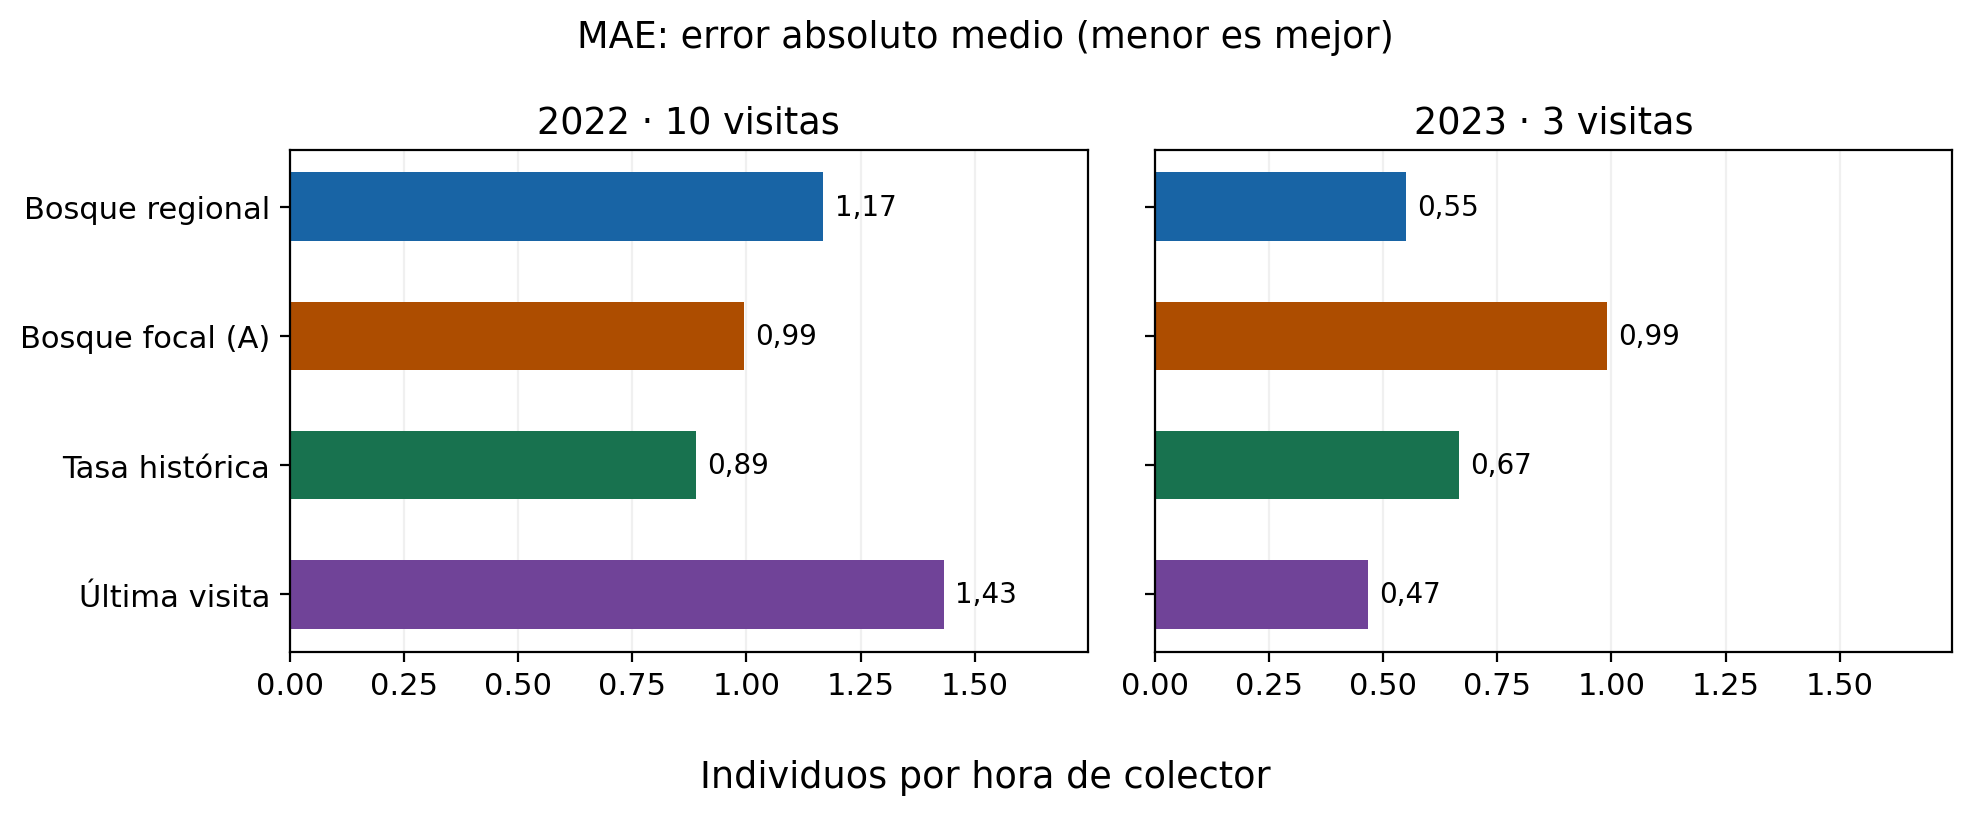

In [27]:
pruebaOriginal = leerZIP(filas=filasReserva)
assert set(pruebaOriginal.eventID) == set(reserva.eventID)
pruebaPreparada = preparar(pruebaOriginal)
_, prueba = agruparVisitas(pruebaPreparada)
assert prueba.visita.tolist() == [20, 21, 22]
assert prueba.fecha.tolist() == fechasBloque.tolist()
assert prueba.inicio.ge(corteFinal).all()

observadoBloque = prueba.cuatroNoches.to_numpy(dtype=float)
mae2023 = predBloque.sub(observadoBloque, axis=0).abs().mean()
cubre = inferiores.le(observadoBloque, axis=0) & superiores.ge(observadoBloque, axis=0)
print(f"Menor MAE en 2022: {mae2022.idxmin()}. En el bloque de 2023: {mae2023.idxmin()}.")
print(f"La banda orientativa de la tasa histórica contiene "
      f"{cubre[nombreHistorica].sum()} de 3 observaciones; no es una validación de cobertura.")

# Solo sustituimos la tasa histórica si un bosque gana a las dos referencias en ambos ejercicios.
referenciasBosques = [nombreHistorica, nombreUltima]
consistentes = [
    n for n in nombresBosques
    if mae2022[n] < mae2022[referenciasBosques].min() and mae2023[n] < mae2023[referenciasBosques].min()
]
recomendado = min(consistentes, key=mae2022.get) if consistentes else nombreHistorica
print(f"Referencia recomendada: {recomendado}.")

# Las diferencias absolutas se promedian sin cancelar excesos con faltantes.
estilosMetodo = {
    bosqueRegional: ("s", "--", coloresFigura["regional"]),
    bosqueFocal: ("^", ":", coloresFigura["focal"]),
    nombreHistorica: ("P", "-.", coloresFigura["historica"]),
    nombreUltima: ("D", "--", coloresFigura["ultima"]),
}
figValidacion, ejesMAE = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(10, 4))
posiciones = np.arange(len(metodos))
maxHora = max(mae2022.max(), mae2023.max()) / esfuerzoObjetivo
for eje, errores, periodo in [
    (ejesMAE[0], mae2022, "2022 · 10 visitas"),
    (ejesMAE[1], mae2023, "2023 · 3 visitas"),
]:
    # Usar el mismo eje para comparar los dos bloques; los MAE internos siguen a 96 h.
    erroresHora = errores[metodos] / esfuerzoObjetivo
    barras = eje.barh(posiciones, erroresHora, height=.53,
                      color=[estilosMetodo[m][2] for m in metodos])
    eje.bar_label(barras, labels=[numero(v, 2) for v in erroresHora], padding=4, fontsize=10)
    eje.set_yticks(posiciones, metodos)
    eje.set(title=periodo, xlim=(0, 1.22 * maxHora))
    eje.grid(axis="x", alpha=.18)
    eje.set_axisbelow(True)
ejesMAE[0].invert_yaxis()
figValidacion.suptitle("MAE: error absoluto medio (menor es mejor)")
figValidacion.supxlabel(unidadTasa)
figValidacion.tight_layout()
plt.show()

### Qué pasó cada mes

En enero se contaron 421 individuos en 192 horas de colector. Son $421/192=2{,}19$ por hora, o 210,5 por 96 horas. La tabla distingue conteos de tasas; la gráfica compara observado y pronosticado por hora. La distancia vertical entre los dos puntos de un mes es el error de ese pronóstico.

,Conteo,Horas de colector,Observado / h,Observado / 96 h,Bosque regional / h,Bosque focal / h
Visita de 2023,,,,,,
Enero,421,192,"2,19","210,5","1,84","2,37"
Febrero,277,192,"1,44","138,5","1,84","2,37"
Marzo,180,192,"0,94","90,0","1,84","2,80"


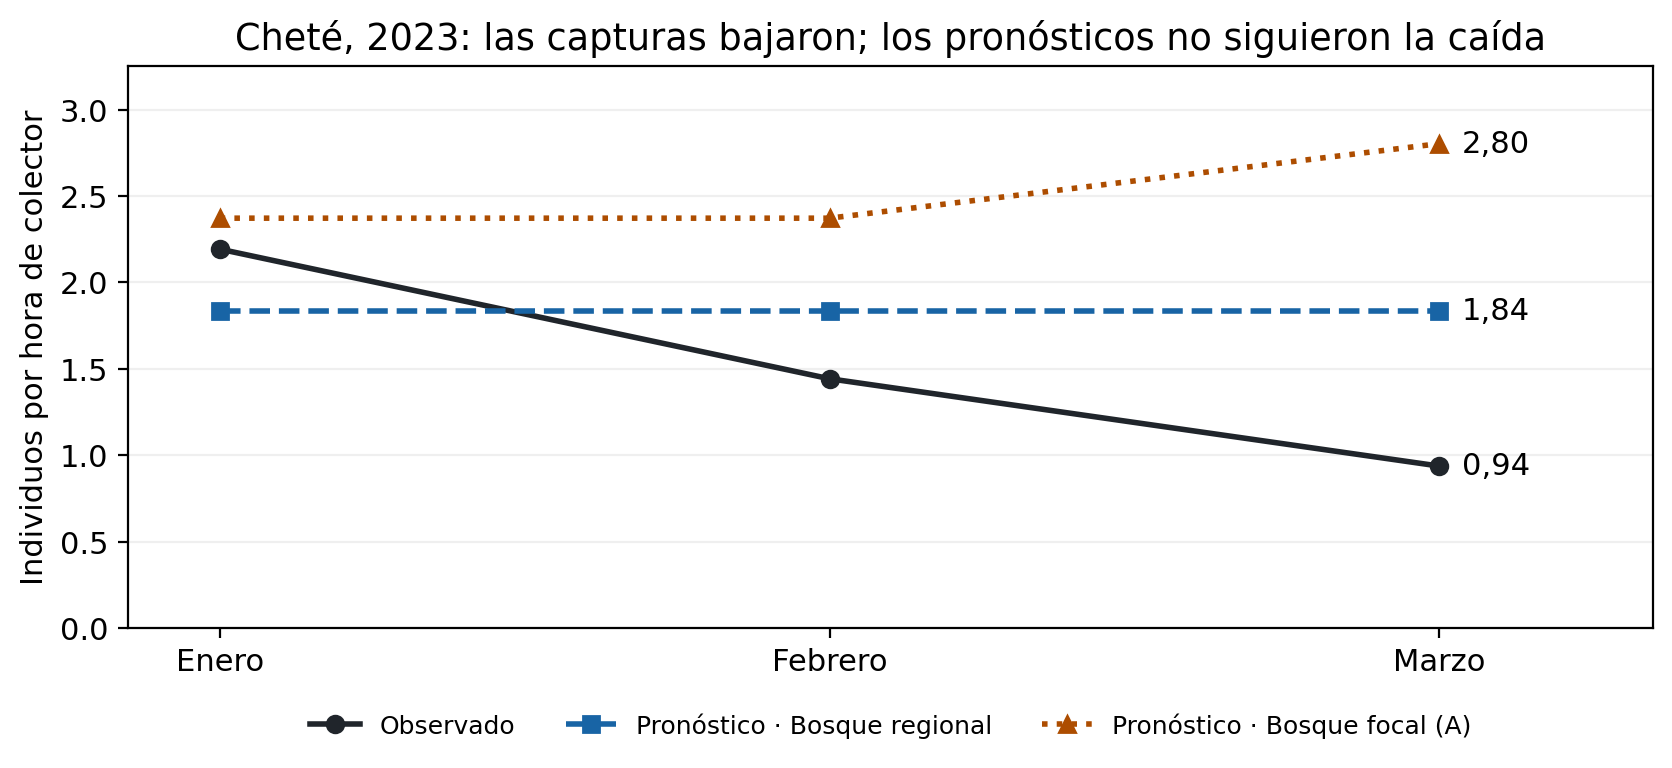

In [28]:
detalle2023 = predBloque.set_axis(pd.DatetimeIndex(prueba.fecha)).copy()
detalle2023.insert(0, "Observado", observadoBloque)
# Mantener el conteo original y mostrar ambas escalas solo para lo observado.
curvaHora = detalle2023[["Observado", *nombresBosques]] / esfuerzoObjetivo
tablaReserva = pd.DataFrame({
    "Conteo": prueba.conteo.to_numpy(),
    "Horas de colector": prueba.esfuerzo.to_numpy(),
    "Observado / h": curvaHora["Observado"].map(lambda v: numero(v, 2)),
    f"Observado / {esfuerzoObjetivo} h": detalle2023["Observado"].map(numero),
    "Bosque regional / h": curvaHora[bosqueRegional].map(lambda v: numero(v, 2)),
    "Bosque focal / h": curvaHora[bosqueFocal].map(lambda v: numero(v, 2)),
}, index=detalle2023.index)
tablaReserva.index = pd.Index([mesesNombre[f.month-1].capitalize() for f in detalle2023.index],
                             name="Visita de 2023")
display(tablaReserva)

fig, ax = plt.subplots(figsize=(8.5, 4))
x = detalle2023.index.month
for col, (marca, trazo, color) in [
    ("Observado", ("o", "-", coloresFigura["observado"])),
    (bosqueRegional, estilosMetodo[bosqueRegional]),
    (bosqueFocal, estilosMetodo[bosqueFocal]),
]:
    # Las tres series comparten escala: su separación vertical es el error del mes.
    serie = curvaHora[col]
    ax.plot(x, serie, marker=marca, ls=trazo, color=color, lw=2, ms=6,
            label=col if col == "Observado" else f"Pronóstico · {col}")
    ax.annotate(numero(serie.iloc[-1], 2), (x[-1], serie.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center")
ax.set(xticks=x, xticklabels=[mesesNombre[m-1].capitalize() for m in x],
       xlim=(.85, 3.35), ylim=(0, 1.16 * curvaHora.max().max()),
       ylabel=unidadTasa,
       title="Cheté, 2023: las capturas bajaron; los pronósticos no siguieron la caída")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.11), ncol=3, frameon=False, fontsize=9)
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

Para ver el sentido del error restamos lo observado a lo predicho. Por encima de cero, el modelo se pasó; por debajo, se quedó corto. Donde no hubo visita no se dibuja ningún error.

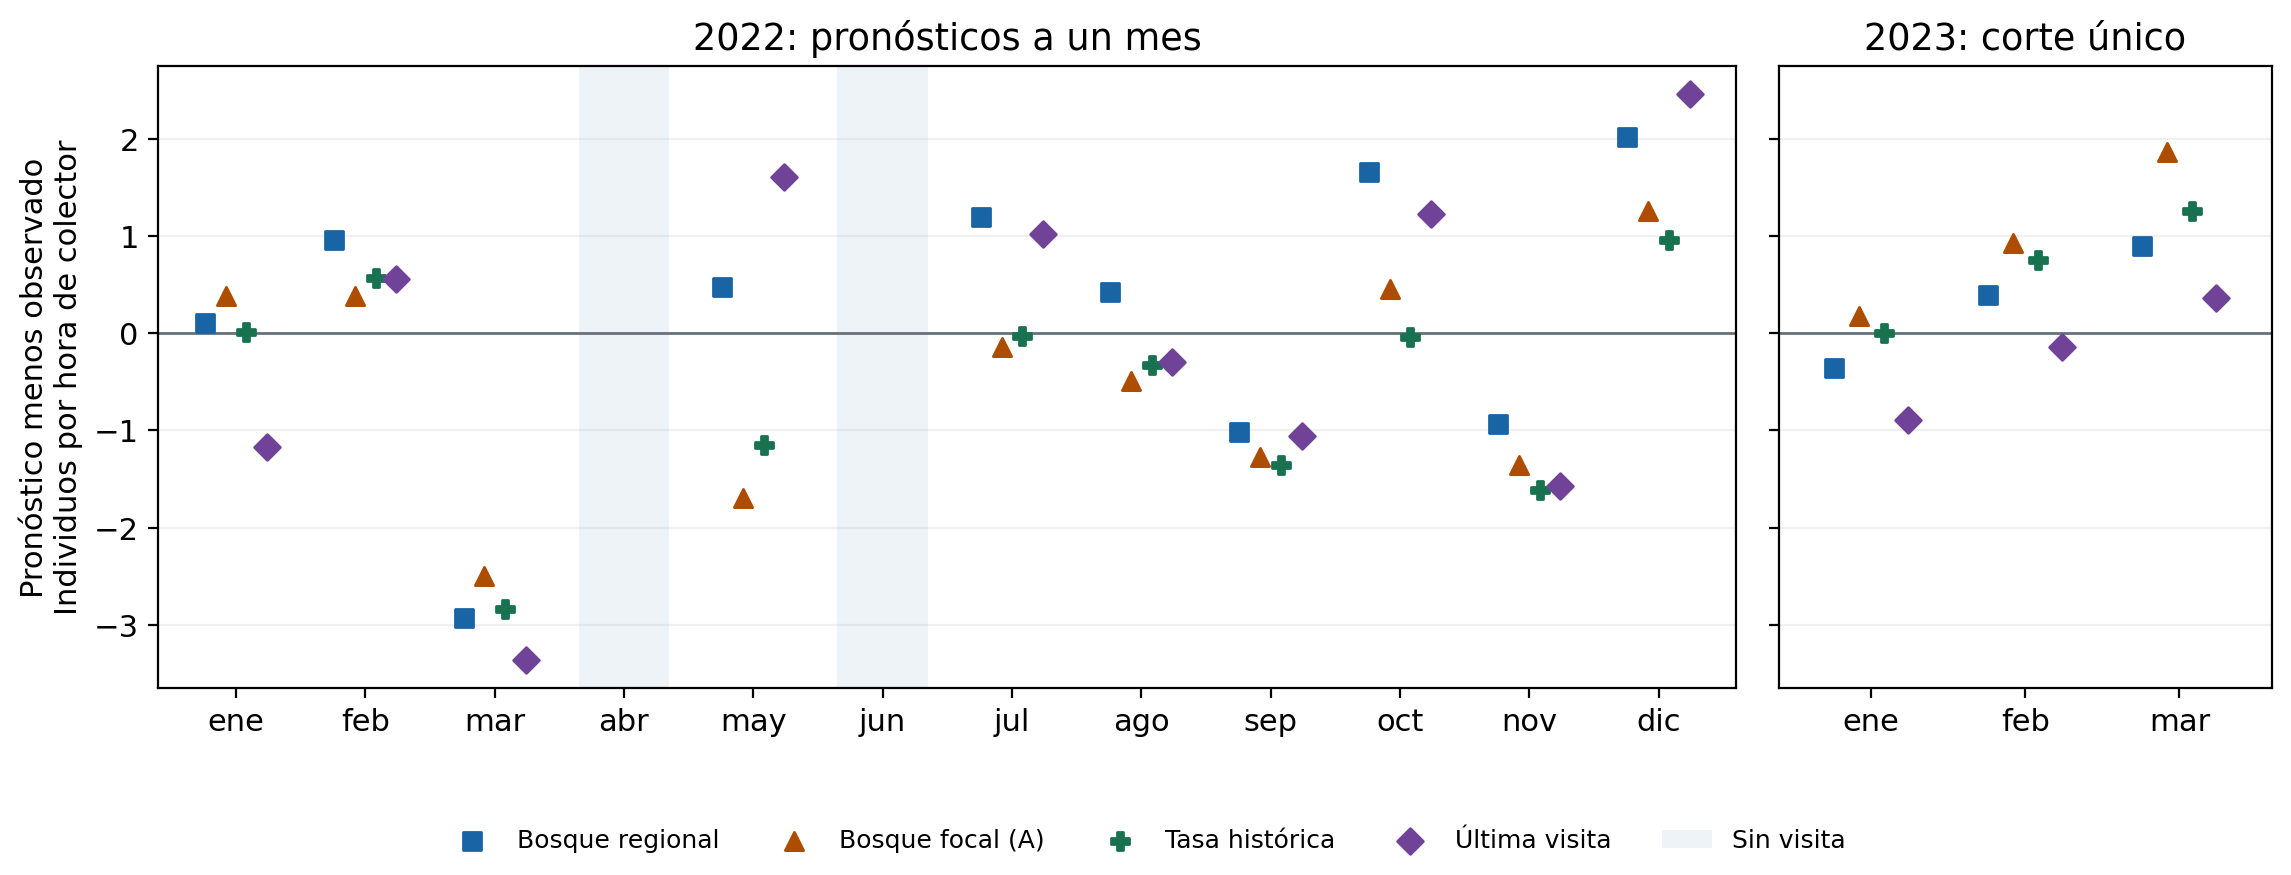

In [29]:
fig, ejes = plt.subplots(1, 2, figsize=(11.6, 4.4), sharey=True,
                         gridspec_kw={"width_ratios": [3.2, 1]})
for ax, detalle, mesesPanel, titulo, maes in [
    (ejes[0], detalle2022, range(1, 13), "2022: pronósticos a un mes", mae2022),
    (ejes[1], detalle2023, range(1, 4), "2023: corte único", mae2023),
]:
    diferencia = detalle[metodos].sub(detalle["Observado"], axis=0)
    assert np.allclose(diferencia.abs().mean(), maes[metodos])
    ax.axhline(0, lw=1, color="#68727b")
    ax.grid(axis="y", alpha=.18)
    for metodo, dx in zip(metodos, (-.24, -.08, .08, .24)):
        # Desplazar marcas dentro de cada mes evita tapar errores casi iguales.
        marca, _, color = estilosMetodo[metodo]
        ax.scatter(detalle.index.month + dx, diferencia[metodo] / esfuerzoObjetivo,
                   marker=marca, color=color, s=43, label=metodo, zorder=3)
    ax.set(xticks=list(mesesPanel), xticklabels=[mesesNombre[m-1][:3] for m in mesesPanel],
           xlim=(min(mesesPanel)-.6, max(mesesPanel)+.6), title=titulo)
ejes[0].set_ylabel(f"Pronóstico menos observado\n{unidadTasa}")
# Las franjas distinguen meses sin visita de un error observado de cero.
ejes[0].axvspan(3.65, 4.35, facecolor="#edf3f7", zorder=-1, label="Sin visita")
ejes[0].axvspan(5.65, 6.35, facecolor="#edf3f7", zorder=-1)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, .11, 1, 1))
plt.show()

En esas mismas tres visitas también podemos comprobar Poisson, que sí había quedado cerrado antes de abrir la reserva. Estimó 2,22; 2,23 y 2,25 por hora. Se observaron 2,19; 1,44 y 0,94. Estuvo cerca en enero, pero no anticipó la caída de los otros dos meses. En promedio falló por 0,71 por hora. Que las tres observaciones entren en una banda ancha no significa que haya acertado sus valores.

In [30]:
# Comprobamos las predicciones congeladas con la misma reserva y los márgenes originales de Poisson.
prediccionesPoisson = referencias(visitas, len(prueba))
prediccionesPoisson["Poisson"] = pronosticoCerrado
comprobacion = []
for nombre, pred in prediccionesPoisson.items():
    error = pred - observadoBloque
    bajo = np.maximum(0, pred - margenes[nombre])
    alto = pred + margenes[nombre]
    dentro = (bajo <= observadoBloque) & (observadoBloque <= alto)
    # El MAE promedia distancias; el RMSE da más peso a los errores grandes. Ambos se muestran por hora.
    etiqueta = nombreHistorica if nombre == "Fermi revisada" else nombre
    comprobacion.append({
        "Método del cierre original": etiqueta,
        "Error medio absoluto/h": numero(abs(error).mean() / esfuerzoObjetivo, 2),
        "Error cuadrático medio (raíz)/h": numero(np.sqrt((error**2).mean()) / esfuerzoObjetivo, 2),
        "Visitas dentro de la banda": f"{dentro.sum()} de {len(dentro)}",
        "Ancho medio de la banda/h": numero((alto-bajo).mean() / esfuerzoObjetivo, 2),
    })
display(pd.DataFrame(comprobacion).set_index("Método del cierre original"))

,Error medio absoluto/h,Error cuadrático medio (raíz)/h,Visitas dentro de la banda,Ancho medio de la banda/h
Método del cierre original,,,,
Última visita,"0,47","0,56",3 de 3,"3,40"
Tasa histórica,"0,67","0,84",3 de 3,"3,23"
Poisson,"0,71","0,88",3 de 3,"3,11"


El número observado bajó de 2,19 por hora en enero a 0,94 en marzo. Para marzo, el bosque regional estimó 1,84 por hora y el local 2,80: ninguno anticipó bien la caída. La tasa histórica tuvo el menor error medio en las diez visitas de 2022 (0,89 por hora). En las tres de 2023 ganó repetir la última visita (0,47); después quedaron el bosque regional (0,55), la tasa histórica (0,67) y el local (0,99). No cambiamos a un bosque porque ninguno mejoró las dos reglas en ambos períodos.

<a id="importancia-random-forest"></a>

### 7.1. Qué información ayudó al bosque

Tomamos el bosque ya entrenado y le desordenamos una pista. Por ejemplo, le damos la tasa anterior de otro mes del mismo sitio. Si aumenta el error, esa pista le servía para predecir. Repetimos con el calendario; para el nombre del sitio, lo mezclamos entre sitios del mismo mes. En Cheté el nombre nunca cambia, así que allí no puede probarse.

En la gráfica, cero significa que el error no cambió. A la derecha empeoró; a la izquierda mejoró en esa muestra. El punto resume 60 mezclas y la raya va del percentil 10 al 90; no es un intervalo de confianza.

In [31]:
def importanciaBloques(casos, grupos, porMes=False, repeticiones=60):
    """Mide cuánto cambia el MAE al desordenar una pista; devuelve media, P10 y P90 por 96 h."""
    entradas = pd.concat([x for _, x, _ in casos], ignore_index=True)
    observado = np.concatenate([y for _, _, y in casos])
    # Como cada corte tiene su propio modelo, conservamos las filas que pertenecen a cada ajuste.
    limites = np.cumsum([len(x) for _, x, _ in casos])[:-1]
    tramos = np.split(np.arange(len(entradas)), limites)
    bloques = tramos if porMes else entradas.groupby("sitio", sort=False).indices.values()
    original = np.concatenate([esfuerzoObjetivo * bosque.predict(x) for bosque, x, _ in casos])
    maeOriginal = np.abs(original - observado).mean()

    # Solo intercambiamos filas dentro del grupo elegido: mismo mes o mismo sitio.
    azar = np.random.default_rng(semilla)
    ordenes = np.tile(np.arange(len(entradas)), (repeticiones, 1))
    for orden in ordenes:
        for bloque in bloques:
            orden[bloque] = azar.permutation(bloque)

    resultados = []
    for variable, columnas in grupos.items():
        sumaErrores = np.zeros(repeticiones)
        for (bosque, x, y), tramo in zip(casos, tramos):
            # Cambia esta pista, no el modelo ni las respuestas observadas. Agrupar las 60 mezclas
            # permite calcularlas de una vez sin cambiar los ejemplos con los que se compara.
            lote = pd.concat([x] * repeticiones, ignore_index=True)
            lote[columnas] = entradas.iloc[ordenes[:, tramo].ravel()][columnas].to_numpy()
            pred = esfuerzoObjetivo * bosque.predict(lote).reshape(repeticiones, len(x))
            sumaErrores += np.abs(pred - y).sum(axis=1)
        cambio = sumaErrores / len(observado) - maeOriginal
        resultados.append([variable, cambio.mean(), *np.quantile(cambio, [.10, .90])])
    return pd.DataFrame(resultados, columns=["Variable", "Cambio", "P10", "P90"])

# El sitio no cambia dentro de Cheté: solo se puede valorar esa pista en el panel regional.
gruposTemporales = {"Última tasa": ["tasaAnterior"], "Calendario": calendarioBosque}
impRegional = pd.concat([
    importanciaBloques(casosRegion, gruposTemporales),
    importanciaBloques(casosRegion, {"Localidad": ["sitio"]}, porMes=True),
]).sort_values("Cambio", ascending=False)
impChete = {n: importanciaBloques(casosChete[n], gruposTemporales) for n in nombresBosques}

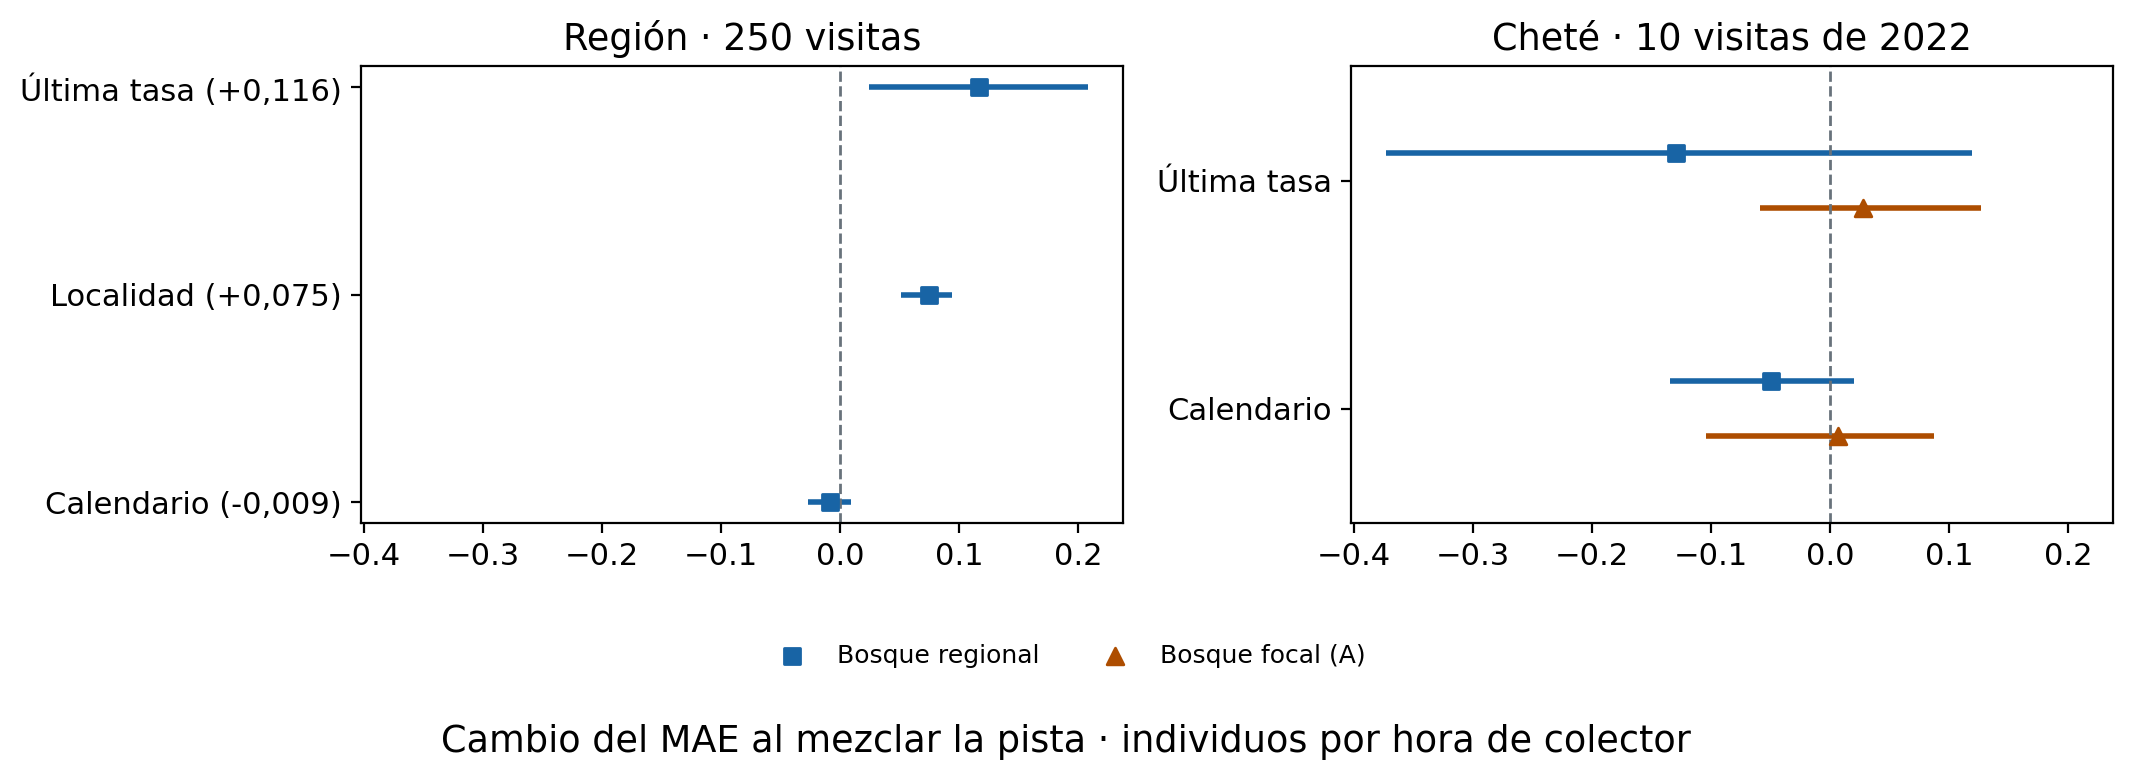

In [32]:
figImportancia, ejes = plt.subplots(1, 2, figsize=(10.8, 3.9), sharex=True)

def dibujarImportancia(ax, resultados, posiciones, color, etiqueta):
    """Dibuja por hora el cambio medio del MAE y sus percentiles; recibe resultados a 96 h."""
    # La raya describe las 60 mezclas, no un intervalo de confianza.
    ax.hlines(posiciones, resultados.P10 / esfuerzoObjetivo,
              resultados.P90 / esfuerzoObjetivo, color=color, linewidth=2)
    ax.scatter(resultados.Cambio / esfuerzoObjetivo, posiciones, color=color,
               marker=estilosMetodo[etiqueta][0], label=etiqueta, zorder=3)

ax = ejes[0]
y = np.arange(len(impRegional))
dibujarImportancia(ax, impRegional, y, coloresFigura["regional"], bosqueRegional)
ax.set_yticks(y, [f"{r.Variable} ({r.Cambio / esfuerzoObjetivo:+.3f})".replace(".", ",")
                  for r in impRegional.itertuples()])
ax.set_title(f"Región · {sum(len(x) for _, x, _ in casosRegion)} visitas")
ax.invert_yaxis()
ax = ejes[1]
y = np.arange(len(gruposTemporales))
# Separar verticalmente ambos bosques para que se vean los tramos superpuestos.
for nombre, ajuste in [(bosqueRegional, -.12), (bosqueFocal, .12)]:
    dibujarImportancia(ax, impChete[nombre], y + ajuste, estilosMetodo[nombre][2], nombre)
ax.set_yticks(y, list(gruposTemporales))
ax.set_title(f"Cheté · {len(casosChete[bosqueFocal])} visitas de 2022")
ax.set_ylim(1.5, -.5)
for ax in ejes:
    ax.axvline(0, color="#68727b", linestyle="--", linewidth=1)
figImportancia.legend(*ejes[1].get_legend_handles_labels(), loc="lower center",
                      bbox_to_anchor=(.5, .10), ncol=2, frameon=False, fontsize=9)
figImportancia.supxlabel("Cambio del MAE al mezclar la pista · individuos por hora de colector")
figImportancia.tight_layout(rect=(0, .12, 1, 1))
plt.show()

En las 250 visitas regionales evaluadas, desordenar la última tasa aumentó el error medio en unos 0,12 individuos por hora; desordenar la localidad, en 0,07. Para el calendario el cambio fue de −0,01. En las diez visitas de Cheté las rayas cruzan cero para ambos bosques: no se distingue un predictor ganador. El nombre de una localidad tampoco mide CO₂, lluvia ni exposición a una mina. Una variable sin medir no tiene un efecto estimado de cero: sencillamente no pudimos evaluarla.

## 8. Ordenar meses no es acertar cantidades

En otro ejercicio nos situamos el 1 de abril de 2022 y pronosticamos los doce meses siguientes sin actualizar los datos. Se observaron diez: mayo y julio a diciembre de 2022; enero, febrero y marzo de 2023. No son las diez visitas de 2022 usadas para el error medio.

Comparamos los meses de dos en dos. Mayo de 2022 tuvo 3,06 individuos por hora y julio 2,04. Poner mayo por encima de julio vale un punto; darles la misma predicción vale medio; invertirlos vale cero. Para no distinguir fracciones irrelevantes, el criterio original redondea al individuo por 96 horas antes de comparar. Hubo 45 pares con cantidades observadas distintas. Comparten visitas y no son 45 ensayos independientes.

In [33]:
# Ya evaluamos la reserva. Ahora podemos recuperar el calendario completo para el diagnóstico de orden.
regional = leerZIP(filas=set(calendario.index))
eventosRegional = reconstruirEventos(regional)
campanasRegional = formarCampanas(eventosRegional)
cheteCompleto = campanasRegional.loc[campanasRegional.sitio.eq(localidadObjetivo)]
assert len(cheteCompleto) == len(visitas) + len(prueba)
assert np.allclose(cheteCompleto.tasa.tail(len(prueba)), prueba.tasa)

# En este contraste nos situamos otra vez en su pasado: 1 de abril de 2022, sin usar el año que sigue.
corteOrden = pd.Timestamp("2022-04-01")
finOrden = corteOrden + pd.DateOffset(years=1)
historiaOrden = campanasRegional.loc[campanasRegional.fin.lt(corteOrden)]
objetivosOrden = cheteCompleto.loc[cheteCompleto.fecha.ge(corteOrden) & cheteCompleto.fecha.lt(finOrden)]
ajustesOrden, _ = ajustarBosques(historiaOrden, corteOrden)
predOrden, _ = pronosticar(ajustesOrden, historiaOrden, objetivosOrden)

def ordenEntrePares(cantidades):
    """Para cada par cronológico indica si el segundo mes bajó, empató o subió frente al primero."""
    # Redondeamos al individuo por 96 h como en el contraste original, no al entero por hora.
    enteros = np.rint(np.asarray(cantidades, dtype=float))
    primeroMes, segundoMes = np.triu_indices(len(enteros), k=1)
    return np.sign(enteros[segundoMes] - enteros[primeroMes])

ordenReal = ordenEntrePares(esfuerzoObjetivo * objetivosOrden.tasa)
compara = ordenReal != 0
aciertosOrden = {}
tablaOrden = []
for nombre in [*nombresBosques, nombreHistorica]:
    ordenPred = ordenEntrePares(predOrden[nombre])[compara]
    # Si el dato observado no fue empate, predecir empate vale medio punto, no un acierto completo.
    puntosOrden = np.where(ordenPred == 0, .5, ordenPred == ordenReal[compara])
    aciertosOrden[nombre] = 100 * puntosOrden.mean()
    tablaOrden.append([nombre, numero(puntosOrden.sum()), int(compara.sum()), numero(aciertosOrden[nombre])+" %"])
display(pd.DataFrame(tablaOrden, columns=["Método", "Puntos", "Pares comparados", "Acierto en el orden"]).set_index("Método"))

,Puntos,Pares comparados,Acierto en el orden
Método,,,
Bosque regional,"18,5",45,"41,1 %"
Bosque focal (A),"27,0",45,"60,0 %"
Tasa histórica,"22,5",45,"50,0 %"


El bosque de Cheté consiguió 27 de 45 puntos (60 %) al ordenar esos meses. No quiere decir que acertara el 60 % de las cantidades. La tasa histórica, que pronostica siempre lo mismo, empató todos los pares: obtuvo 50 % sin distinguir un solo mes.

### La referencia para abril de 2023

Esta vez sí incorporamos enero, febrero y marzo. Sumamos los individuos de las 22 visitas de Cheté y dividimos por todas sus horas: 2,08 por hora, o unos 200 por 96 horas de colector. Como esta regla no usa el mes, devuelve lo mismo en abril y en noviembre. La línea plana es una decisión del método, no evidencia de que los meses tendrán las mismas capturas.

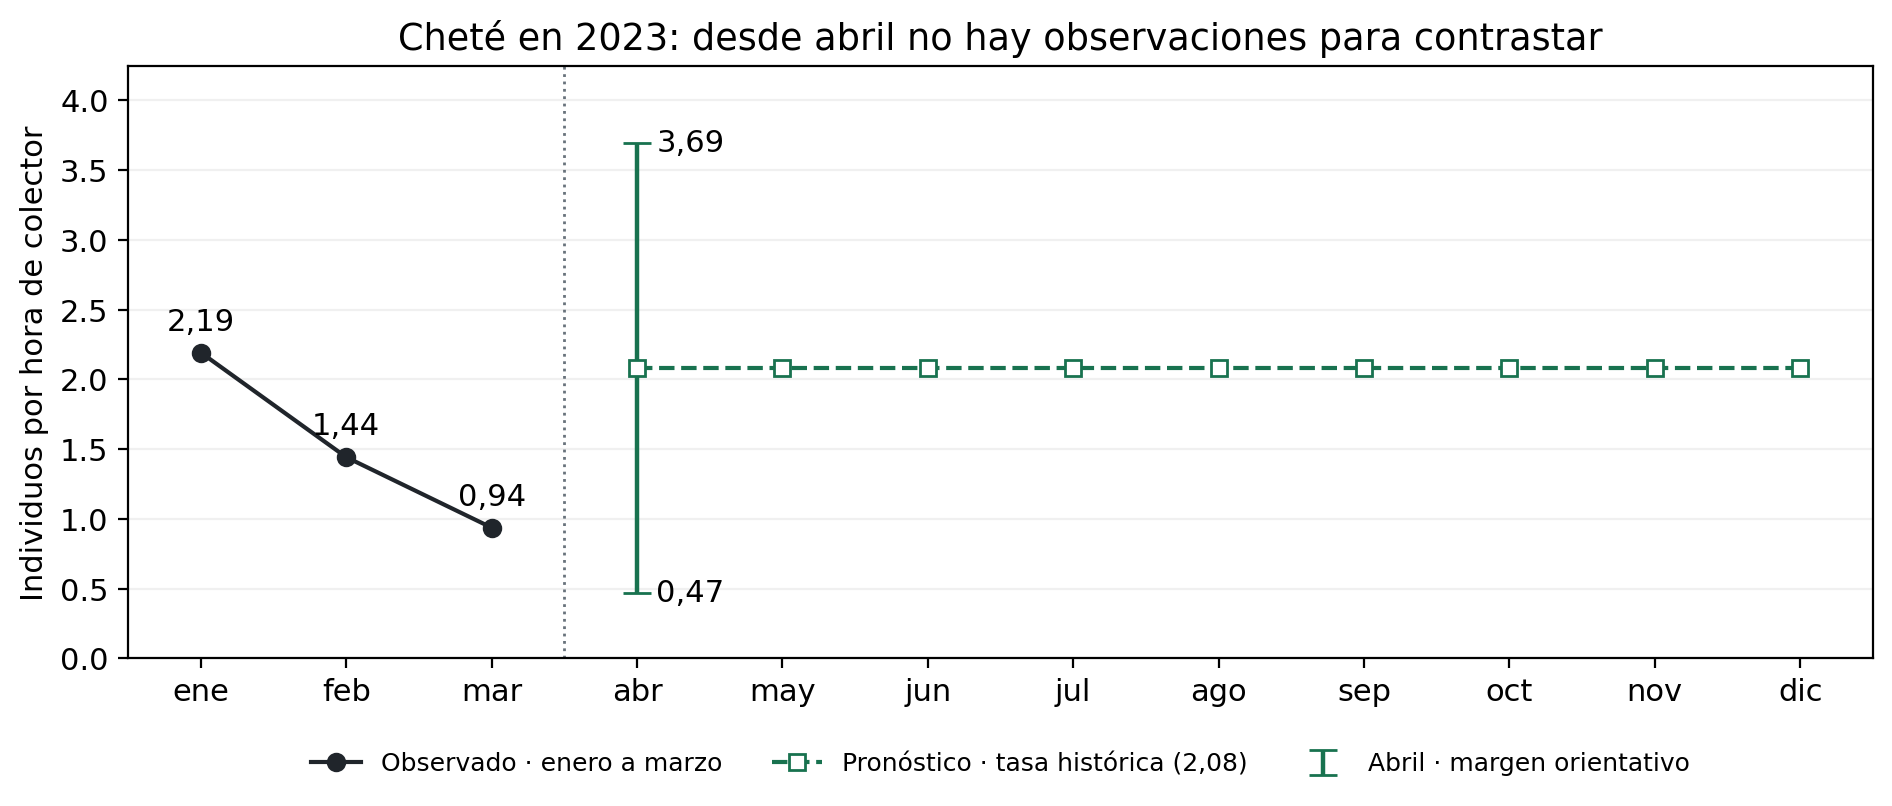

In [34]:
cortePronostico = pd.Timestamp("2023-04-01")
assert cheteCompleto.fin.lt(cortePronostico).all()
assert recomendado == nombreHistorica  # La regla de comparación conserva esta referencia en el ZIP.
prevision = esfuerzoObjetivo * tasaConjunta(cheteCompleto)
margenAbril = margenesHorizonte[1][nombreHistorica]
abrilBajo, abrilAlto = max(0, prevision - margenAbril), prevision + margenAbril
# Mostrar en una hora sin cambiar la referencia ni los márgenes calculados a 96 h.
previstoHora, bajoHora, altoHora = np.array([prevision, abrilBajo, abrilAlto]) / esfuerzoObjetivo
observadoHora = observadoBloque / esfuerzoObjetivo
figPronostico, ax = plt.subplots(figsize=(9.6, 4.2))
pasados = prueba.fecha.dt.month.to_numpy()
futuros = np.arange(cortePronostico.month, 13)
ax.axvline(3.5, ls=":", lw=1, color="#68727b")
ax.plot(pasados, observadoHora, "o-", color=coloresFigura["observado"],
        label="Observado · enero a marzo", zorder=3)
for m, valor in zip(pasados, observadoHora):
    # Mostrar la tasa de cada visita sin conectar observaciones con pronósticos.
    ax.annotate(numero(valor, 2), (m, valor), xytext=(0, 8), textcoords="offset points", ha="center")
ax.plot(futuros, np.repeat(previstoHora, len(futuros)), "s--", color=coloresFigura["historica"],
        mfc="white", label=f"Pronóstico · tasa histórica ({numero(previstoHora, 2)})", zorder=3)
# Solo abril usa el margen calibrado a un mes; no se replica en el tramo plano.
ax.errorbar(4, previstoHora, yerr=[[previstoHora - bajoHora], [altoHora - previstoHora]],
            color=coloresFigura["historica"], fmt="none", lw=1.6, capsize=5,
            label="Abril · margen orientativo")
for valor in (bajoHora, altoHora):
    ax.annotate(numero(valor, 2), (4, valor), xytext=(7, 0), textcoords="offset points", va="center")
ax.set(xticks=range(1, 13), xticklabels=[m[:3] for m in mesesNombre],
       xlim=(.5, 12.5), ylim=(0, altoHora * 1.15), ylabel=unidadTasa,
       title="Cheté en 2023: desde abril no hay observaciones para contrastar")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=3, frameon=False, fontsize=9)
ax.grid(axis="y", alpha=.18)
figPronostico.tight_layout()
plt.show()

Hasta marzo hay observaciones; desde abril solo hay una referencia. El margen orientativo para el primer mes deja abril entre 0,47 y 3,69 por hora (aproximadamente 45–354 si fueran 96 horas). El archivo no trae visitas posteriores de Cheté para medir el acierto de esa línea. No extendemos el margen de abril hasta noviembre o diciembre.

Los cerca de 200 de esa campaña humana no son los 200 mosquitos por frasco y noche de la Fermi. Mantener noviembre por comparabilidad tampoco significa que sea el mes con más capturas.

## De Cheté al resto del estudio

Terminada la evaluación, contrastamos el ZIP completo con el resumen publicado por el INS. Para los dos noviembres de Cheté mostramos tres formas de resumir las tasas: ponderar por las horas, dar igual peso a cada punto o dar el mismo peso también a los años. Cambia el promedio, no los conteos originales. El total del estudio incluye a Cheté y no es el panel de localidades externas de la comparación de especies.

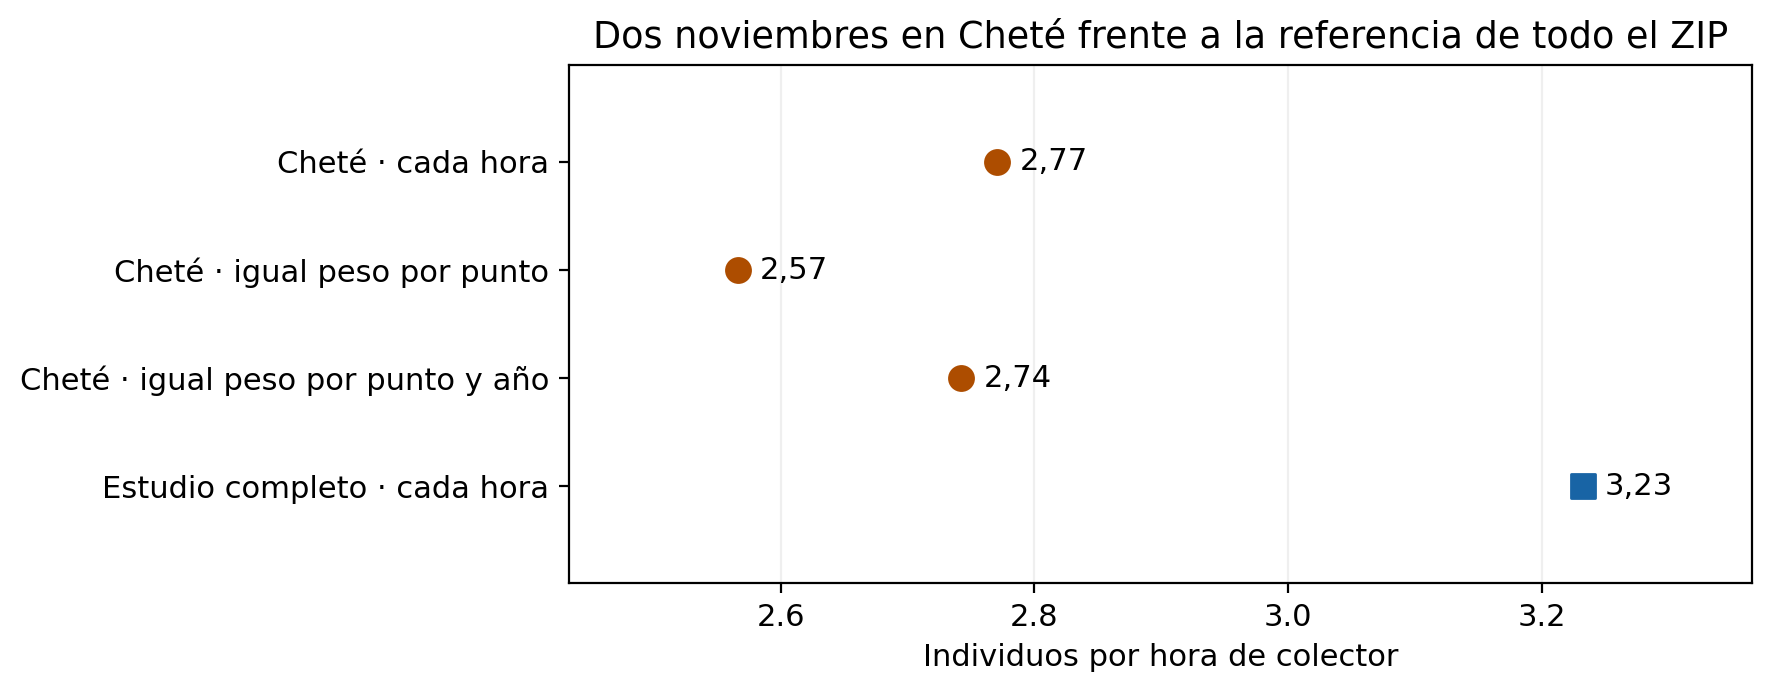

In [35]:
# Primero sumamos individuos y horas; recién después sacamos la tasa.
porPunto = puntosNoviembre.groupby("parentEventID")[["conteo", "esfuerzo"]].sum()
porPuntoAnio = puntosNoviembre.groupby(["parentEventID", "fecha"])[["conteo", "esfuerzo"]].sum()
valores96 = {
    "Cheté · cada hora": esfuerzoObjetivo * tasaConjunta(puntosNoviembre),
    "Cheté · igual peso por punto": esfuerzoObjetivo * (porPunto.conteo / porPunto.esfuerzo).mean(),
    "Cheté · igual peso por punto y año": esfuerzoObjetivo * (porPuntoAnio.conteo / porPuntoAnio.esfuerzo).mean(),
    "Estudio completo · cada hora": esfuerzoObjetivo * tasaConjunta(eventosRegional),
}
assert eventosRegional.conteo.sum() == individuosResumen and len(regional) == registrosResumen
assert regional.sex.eq("Hembra").all() and regional.lifeStage.eq("Adulto").all()
# Comparar ponderaciones y alcance geográfico en la unidad de lectura común.
fig, ax = plt.subplots(figsize=(9, 3.6))
pos = np.arange(len(valores96))
referenciasHora = np.array(list(valores96.values())) / esfuerzoObjetivo
for y, valor in zip(pos, referenciasHora):
    color, marca = ("regional", "s") if y == pos[-1] else ("focal", "o")
    ax.scatter(valor, y, color=coloresFigura[color], marker=marca, s=75, zorder=3)
    ax.annotate(numero(valor, 2), (valor, y), xytext=(8, 0), textcoords="offset points", va="center")
ax.set(yticks=pos, yticklabels=list(valores96), xlabel=unidadTasa,
       title="Dos noviembres en Cheté frente a la referencia de todo el ZIP")
ax.margins(x=.20, y=.3)
ax.invert_yaxis()
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
plt.show()

En el mapa solo entran eventos con una posición WGS84 inequívoca. Un evento sin coordenada fiable sigue contando en los totales. El color señala capturas por hora, no riesgo de malaria ni exposición minera. El resumen del INS declara 25 localidades; el archivo distingue 27 combinaciones de municipio y localidad. No fusionamos nombres sin comprobar que designen el mismo sitio.

In [36]:
camposXY = ["decimalLongitude", "decimalLatitude"]
xy = regional[claveEvento + camposXY + ["geodeticDatum"]].copy()
xy[camposXY] = xy[camposXY].apply(pd.to_numeric, errors="coerce")
# Los límites en grados descartan coordenadas no válidas, no los conteos de los eventos.
validas = (
    xy.geodeticDatum.eq("WGS84")
    & xy.decimalLongitude.between(-180, 180)
    & xy.decimalLatitude.between(-90, 90)
)
catalogo = xy.loc[validas, claveEvento + camposXY].drop_duplicates()
# Solo se dibujan eventos con una posición inequívoca; otros siguen en el total regional.
unicas = catalogo.loc[~catalogo.duplicated(claveEvento, keep=False)]
eventosUbicados = eventosRegional.merge(unicas, on=claveEvento, validate="one_to_one")
# Una posición puede reunir eventos distintos: no se promedian sus tasas sin ponderar.
mapaRegional = eventosUbicados.groupby(camposXY, as_index=False)[["conteo", "esfuerzo"]].sum()
mapaRegional["tasa"] = mapaRegional.conteo / mapaRegional.esfuerzo
coberturaMapa = eventosUbicados.conteo.sum() / eventosRegional.conteo.sum()
print(f"El mapa conserva {len(mapaRegional)} posiciones y {coberturaMapa:.1%} de los individuos.")

El mapa conserva 40 posiciones y 92.8% de los individuos.


In [37]:
archivoLimites = datos / "limites_pacifico.geojson"
with archivoLimites.open(encoding="utf-8") as fuenteMapa:
    limites = json.load(fuenteMapa)["features"]
colombia = next(f["geometry"] for f in limites if f["properties"]["nivel"] == "pais")
municipios = {
    f["properties"]["nombre"]: f["geometry"]
    for f in limites if f["properties"]["nivel"] == "municipio"
}


def anillosPorPoligono(geometria):
    """Devuelve los anillos de cada polígono GeoJSON en grados de longitud y latitud."""
    if geometria["type"] == "Polygon":
        return [geometria["coordinates"]]
    assert geometria["type"] == "MultiPolygon"
    return geometria["coordinates"]


def enPoligonos(posiciones, geometria):
    """Indica qué posiciones en grados caen dentro de la geometría GeoJSON, sin sus huecos."""
    dentro = np.zeros(len(posiciones), dtype=bool)
    for exterior, *huecos in anillosPorPoligono(geometria):
        enExterior = Trayectoria(exterior).contains_points(posiciones)
        for hueco in huecos:
            enExterior &= ~Trayectoria(hueco).contains_points(posiciones)
        dentro |= enExterior
    return dentro


def pintarPoligonos(eje, geometria, relleno, borde, grosor=.7):
    """Dibuja la geometría GeoJSON en el eje con el estilo dado y borde en puntos; no devuelve nada."""
    for anillos in anillosPorPoligono(geometria):
        trazados = [Trayectoria(anillo, closed=True) for anillo in anillos]
        eje.add_patch(PathPatch(Trayectoria.make_compound_path(*trazados), facecolor=relleno,
                                edgecolor=borde, linewidth=grosor, zorder=0))


# Se comprueba cada posición distinta contra su municipio publicado, no una vez por evento.
chequeoMunicipio = eventosUbicados[["county", *camposXY]].drop_duplicates()
coinciden = pd.Series(False, index=chequeoMunicipio.index)
for nombre, grupo in chequeoMunicipio.groupby("county"):
    coinciden.loc[grupo.index] = enPoligonos(
        grupo[camposXY].to_numpy(dtype=float), municipios[nombre.upper()]
    )
print(f"Coordenadas dentro del municipio publicado: {coinciden.sum()} de {len(coinciden)}.")
assert coinciden.all()

Coordenadas dentro del municipio publicado: 40 de 40.


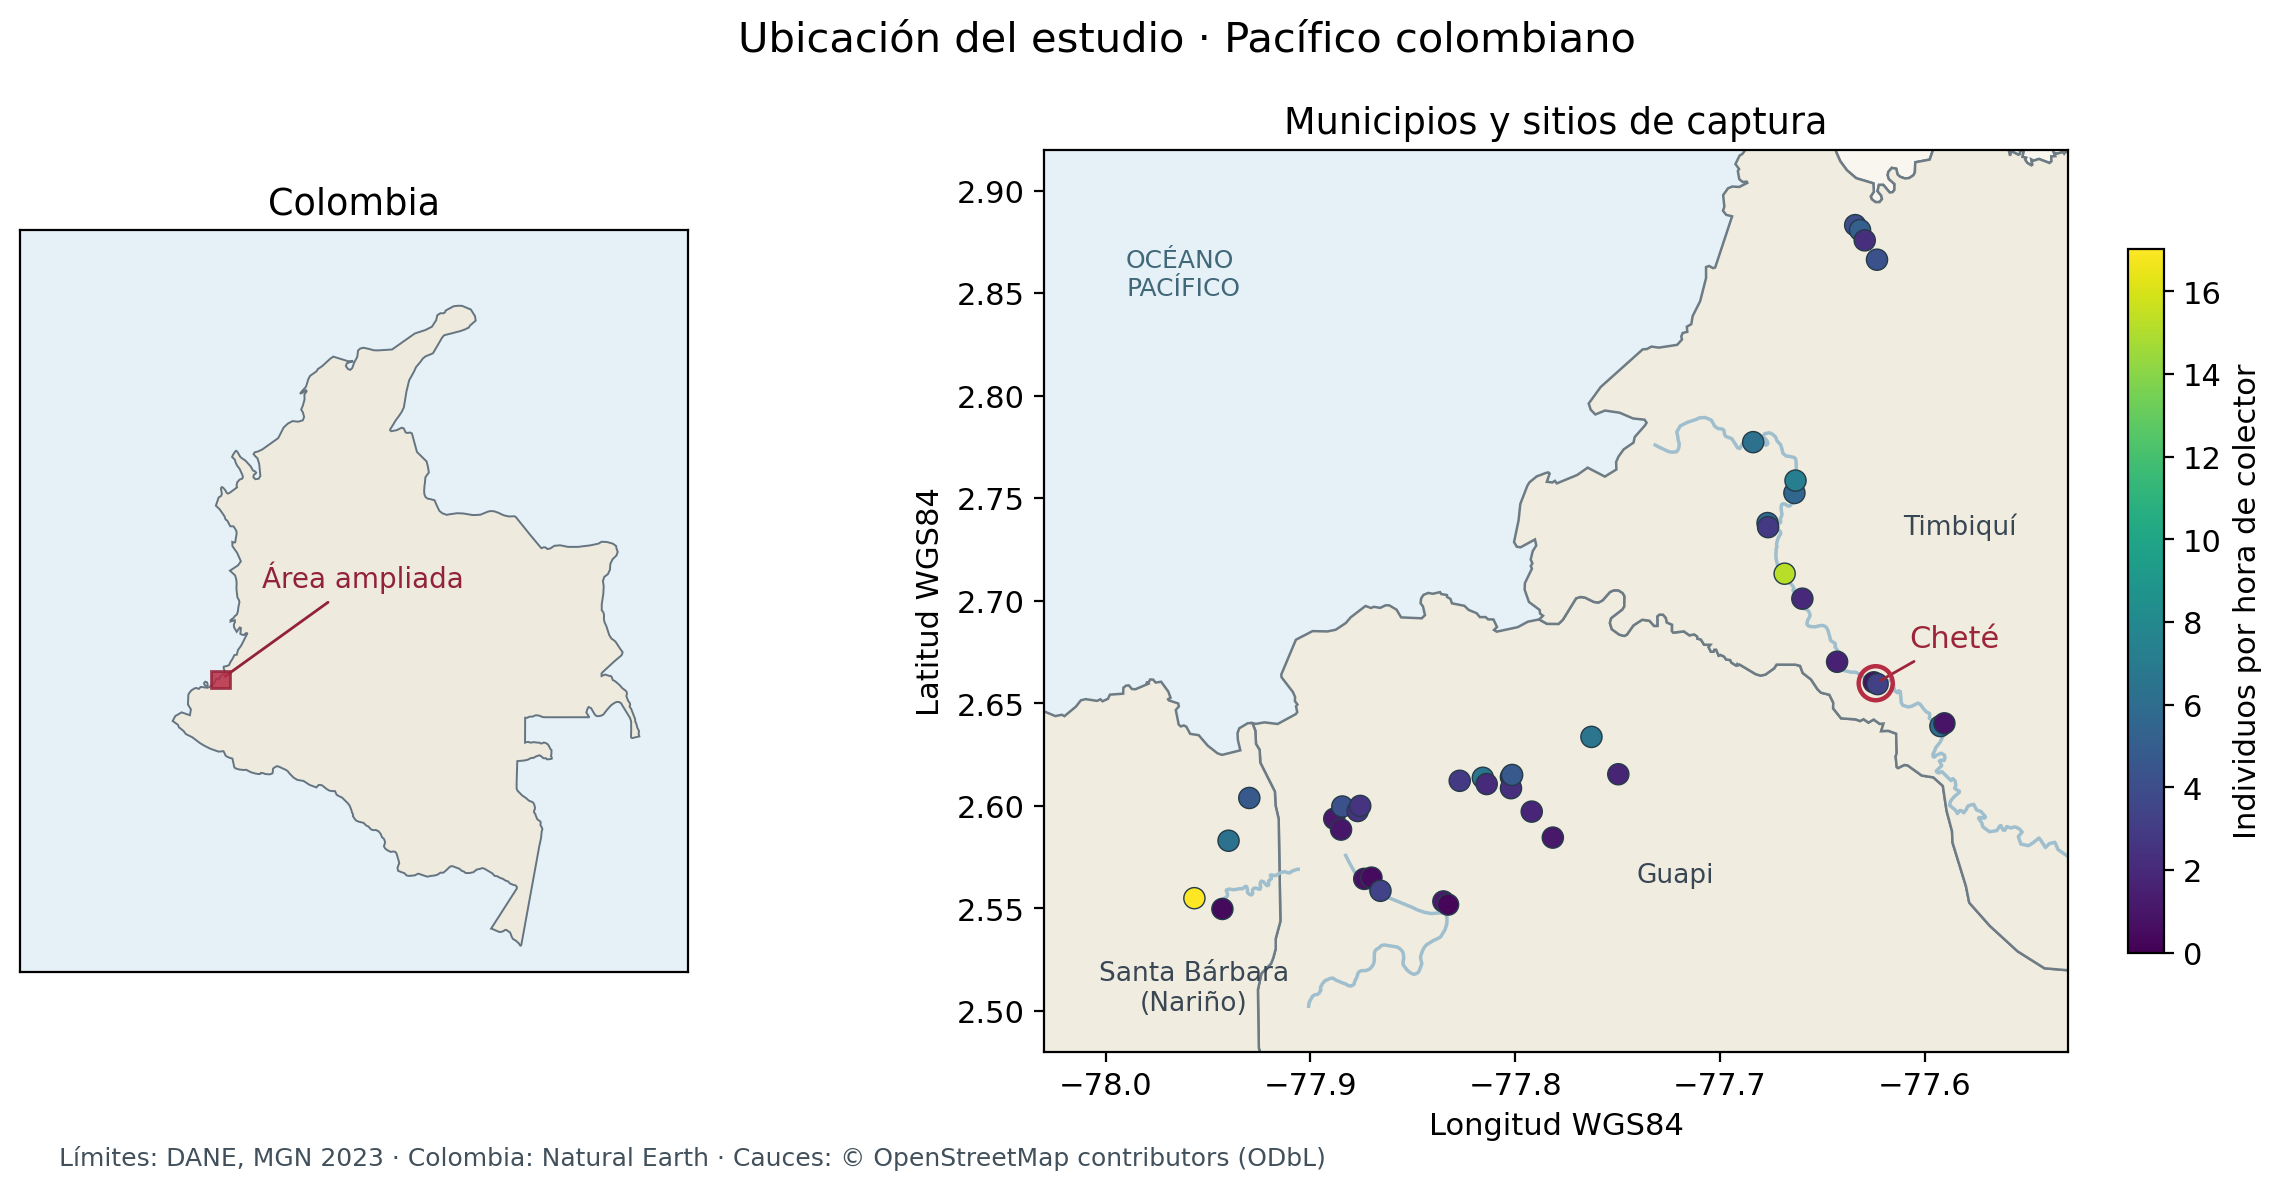

In [38]:
encuadre = (-78.03, -77.53, 2.48, 2.92)
figMapaRegional, (axPais, ax) = plt.subplots(
    1, 2, figsize=(12, 6.1), gridspec_kw={"width_ratios": [1, 2.25]}
)
pintarPoligonos(axPais, colombia, "#eeeadd", "#647480")
x0, x1, y0, y1 = encuadre
axPais.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="#b62c43",
                           ec="#92213a", alpha=.85, zorder=4))
axPais.annotate("Área ampliada", ((x0 + x1) / 2, (y0 + y1) / 2),
                xytext=(-76.7, 5.1), color="#92213a", fontsize=10,
                arrowprops={"arrowstyle": "-", "color": "#92213a"})
axPais.set(xlim=(-83, -65.6), ylim=(-4.9, 14.4), aspect="equal", title="Colombia")
axPais.set_xticks([])
axPais.set_yticks([])
axPais.set_facecolor("#e6f0f7")

dibujarCauces(ax)
ax.set_facecolor("#e6f0f7")
# El relleno delimita los municipios; la tasa se lee únicamente en los puntos.
for nombre, geometria in municipios.items():
    fondo = "#f0ecdf" if nombre in {"TIMBIQUÍ", "GUAPI", "SANTA BÁRBARA"} else "#f8f6ef"
    pintarPoligonos(ax, geometria, fondo, "#6d7b85", .9)
ax.text(-77.99, 2.872, "OCÉANO\nPACÍFICO", color="#406879", fontsize=9, va="top")
for textoMapa, x, y in [
    ("Timbiquí", -77.555, 2.736), ("Guapi", -77.722, 2.566),
    ("Santa Bárbara\n(Nariño)", -77.957, 2.511)
]:
    ax.text(x, y, textoMapa, ha="right" if textoMapa == "Timbiquí" else "center",
            va="center", color="#394653", fontsize=9.5, zorder=2)

# El mapa ya usa conteo / horas de colector; no necesita otra conversión.
puntosMapa = ax.scatter(mapaRegional.decimalLongitude, mapaRegional.decimalLatitude,
                        c=mapaRegional.tasa, cmap="viridis", vmin=0, s=58,
                        edgecolors="#253b48", linewidths=.5, zorder=3)
xyChete = eventosUbicados.loc[(eventosUbicados.county == "Timbiquí") & (eventosUbicados.locality == "Cheté"), camposXY]
cx, cy = xyChete.drop_duplicates().mean()
ax.scatter(cx, cy, marker="o", s=150, facecolors="none", edgecolors="#b62c43",
           lw=1.6, zorder=4)
ax.annotate("Cheté", (cx, cy), xytext=(12, 13), textcoords="offset points",
            color="#9d253a", arrowprops={"arrowstyle": "-", "color": "#9d253a"})
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Municipios y sitios de captura", xlabel="Longitud WGS84", ylabel="Latitud WGS84")
ax.set_aspect(1 / np.cos(np.radians(cy)))
figMapaRegional.suptitle("Ubicación del estudio · Pacífico colombiano", fontsize=15, y=.96)
figMapaRegional.colorbar(puntosMapa, ax=ax, shrink=.78, pad=.04, label="Individuos por hora de colector")
figMapaRegional.text(.03, .021,
                     "Límites: DANE, MGN 2023 · Colombia: Natural Earth · Cauces: © OpenStreetMap contributors (ODbL)",
                     fontsize=9, color="#41505b")
figMapaRegional.tight_layout(rect=(0, .055, 1, .94))
plt.show()

## Qué esperaríamos en la próxima visita y qué haríamos distinto

Para una visita a Cheté en abril de 2023 tomaríamos como referencia 2,08 hembras adultas de *Anopheles* por hora de colector. En 96 horas de trabajo humano esperaríamos unas 200, con un rango orientativo de 45 a 354 según los errores de pronóstico a un mes. El último registro de Cheté es de marzo, por lo que abril quedó como una previsión pendiente de contraste.

Al principio habíamos supuesto 200 mosquitos por frasco y noche. Para volver a esa pregunta, la próxima vez registraríamos las capturas de los frascos y de los colectores en condiciones comparables, junto con las horas de cada uno. Así podríamos estimar $q$ y pasar de una tasa humana a una estimación para nuestros cuatro frascos.

Mantendríamos noviembre para comparar con los noviembres ya observados. Registraríamos también el CO₂ ambiental junto con la hora de cada lectura y la lluvia de cada fecha. Eso permitiría estudiar posibles explicaciones para las diferencias de captura entre puntos. Con los registros actuales sigue abierta la causa de la diferencia entre Chete1 y Chete2.

La IA ayudó a contrastar unidades, revisar el código y comprobar las figuras. Las decisiones y la reflexión personal corresponden a los integrantes del equipo.

### Fuentes y presentación

[INS v1.0, DOI 10.15472/kftrcn](https://doi.org/10.15472/kftrcn), [CDC: ciclo de Anopheles](https://www.cdc.gov/mosquitoes/about/life-cycle-of-anopheles-mosquitoes.html), [Ellwanger y colaboradores](https://pubmed.ncbi.nlm.nih.gov/35284885/), [DANE MGN 2023](https://geoportal.dane.gov.co/descargas/mgn_2023/MGN2023_CatalogoDeObjetos.pdf), [Natural Earth](https://www.naturalearthdata.com/about/terms-of-use/) y [OpenStreetMap](https://www.openstreetmap.org/copyright). Datos del INS: CC BY-NC 4.0.

[Presentación del equipo sobre Cheté (15 diapositivas)](Chete_sustentacion_15.pdf).